---
# Atividade de comparação dos modelos


*   Aluno: Livia Keche de Oliveira
*   RGM: 11261401806

Aqui vamos fazer a comparação do modelo aprendido (SVM) e os novo ensinados na última aula *26/10/2026*

Cada dataset terá a sua sessão para não confundir quem estiver lendo este notebook e ao final das seções, temos a conclusão desse estudo dos modelos. Todos os notebooks vieram das atividades anteriores, apenas adicionando os novos modelo pois como o professor falou, o que muda são 3 linhas.


---
# Breast Cancer Wisconsin (Diagnostic) Data Set

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Path to dataset files: /kaggle/input/breast-cancer-wisconsin-data


In [ ]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import os

path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

df_cancer = pd.read_csv(os.path.join(path, "data.csv"))

if 'id' in df_cancer.columns:
    df = df_cancer.drop(columns=['id'])
else:
    df = df_cancer.copy()

df = df.dropna(how='all', axis='columns')

df.head()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Aqui pegamos os dados, seus tipos e fizemos as contagens e estatísticas.

In [ ]:
# Mostra Linhas e Colunas
print("Formato dop dataset:", df.shape)
# Informações de tipos de dados e valores (null)
print("\n  Informação das Colunas")
df.info()

# Contagem de cancêr maligno e benigno
print("\n Contagem por Diagnóstico")
print(df['diagnosis'].value_counts())
# Resumo estatístico das variáveis
display(df.describe())

Formato dop dataset: (569, 31)

  Informação das Colunas
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se           

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


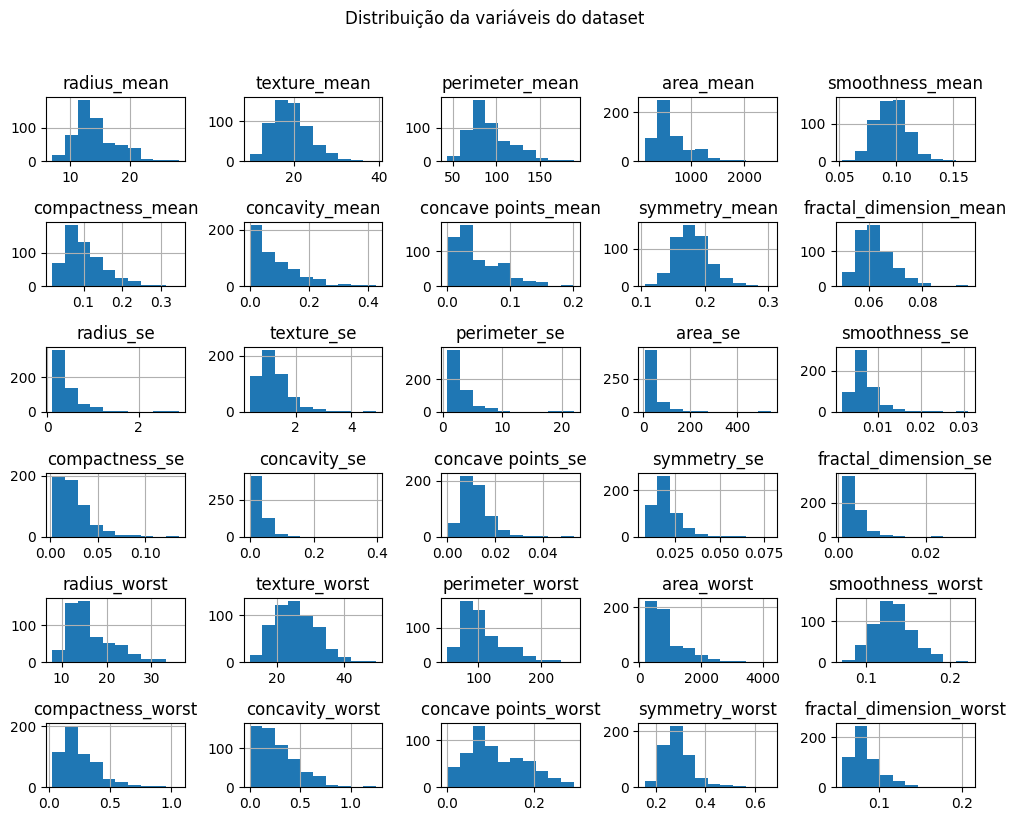

In [ ]:
# Histogramas de Distribuição
df.drop(columns=['diagnosis']).hist(figsize=(10, 8))
plt.suptitle("Distribuição da variáveis do dataset", y = 1.02)

plt.tight_layout()
plt.show()

In [ ]:
# Dicionário com todos os modelos
models = {
    "SVM (Linear)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='linear', random_state=42))]),
    "SVM (RBF)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', random_state=42))]),
    "SVM (Polinomial)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='poly', degree=3, random_state=42))]),
    "SVM (Sigmoide)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='sigmoid', random_state=42))]),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Floresta Aleatória": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

In [ ]:
# 1. Separa as variáveis explicativas (X) da variável alvo (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# 2. Divide os dados em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

=== SVM (Linear) ===
Acurácia Média (CV): 0.9648
Acurácia no Teste: 0.9649

              precision    recall  f1-score   support

           B       0.95      1.00      0.97        72
           M       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



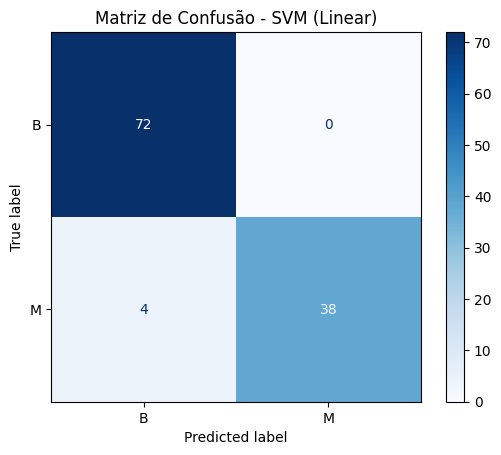

--------------------------------------------------
=== SVM (RBF) ===
Acurácia Média (CV): 0.9736
Acurácia no Teste: 0.9737

              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



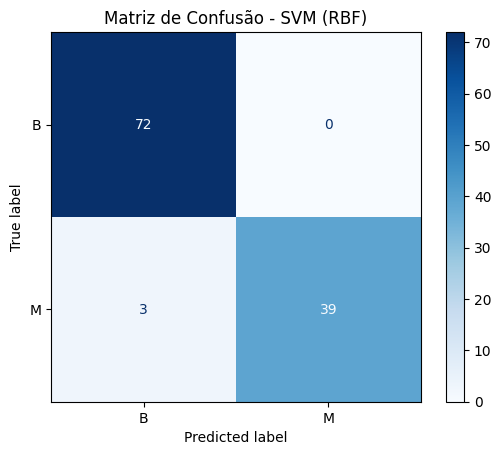

--------------------------------------------------
=== SVM (Polinomial) ===
Acurácia Média (CV): 0.9011
Acurácia no Teste: 0.8860

              precision    recall  f1-score   support

           B       0.85      1.00      0.92        72
           M       1.00      0.69      0.82        42

    accuracy                           0.89       114
   macro avg       0.92      0.85      0.87       114
weighted avg       0.90      0.89      0.88       114



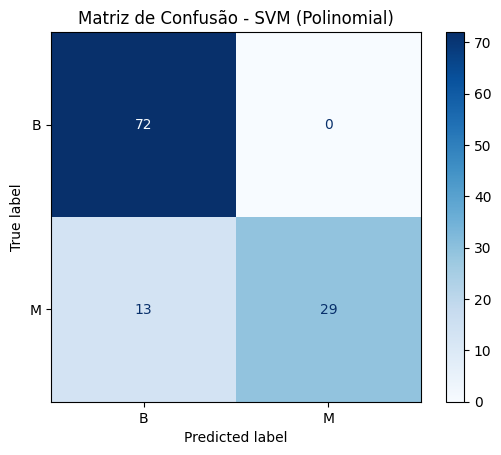

--------------------------------------------------
=== SVM (Sigmoide) ===
Acurácia Média (CV): 0.9560
Acurácia no Teste: 0.9474

              precision    recall  f1-score   support

           B       0.93      0.99      0.96        72
           M       0.97      0.88      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



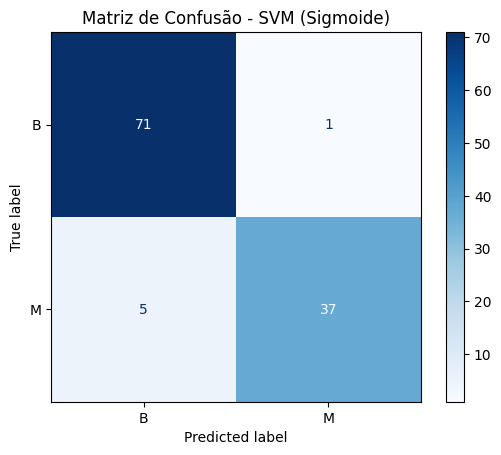

--------------------------------------------------
=== Árvore de Decisão ===
Acurácia Média (CV): 0.9319
Acurácia no Teste: 0.9298

              precision    recall  f1-score   support

           B       0.94      0.94      0.94        72
           M       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



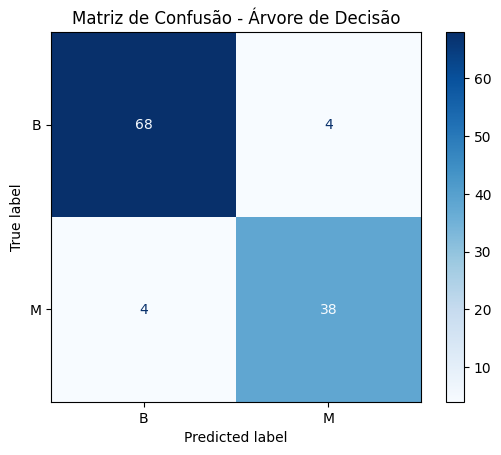

--------------------------------------------------
=== Floresta Aleatória ===
Acurácia Média (CV): 0.9626
Acurácia no Teste: 0.9737

              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



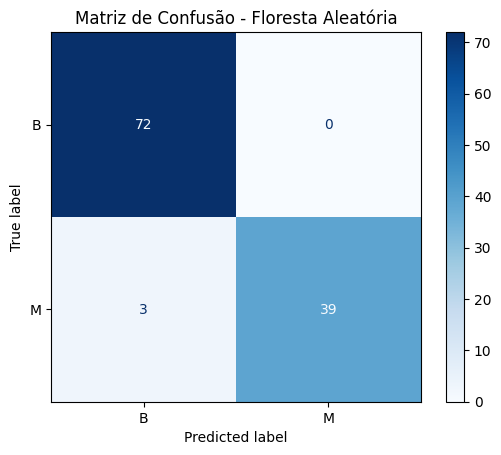

--------------------------------------------------
=== Gradient Boosting ===
Acurácia Média (CV): 0.9538
Acurácia no Teste: 0.9649

              precision    recall  f1-score   support

           B       0.95      1.00      0.97        72
           M       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



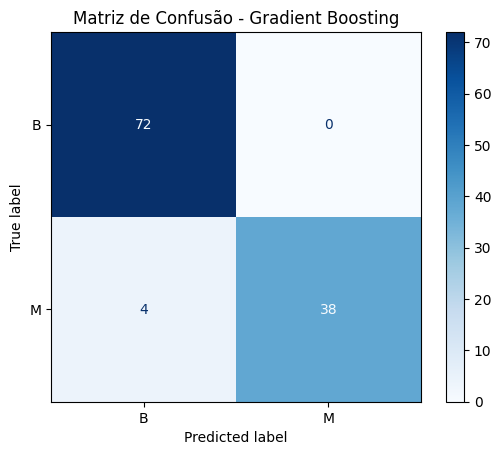

--------------------------------------------------


In [ ]:
results = {}

for name, model in models.items():
    # Validação cruzada (5 folds)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

    # Treino no conjunto de treino completo
    model.fit(X_train, y_train)

    # Predição no conjunto de teste
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'CV Mean Accuracy': cv_scores.mean(),
        'Test Accuracy': test_acc
    }

    print(f"=== {name} ===")
    print(f"Acurácia Média (CV): {cv_scores.mean():.4f}")
    print(f"Acurácia no Teste: {test_acc:.4f}\n")
    print(classification_report(y_test, y_pred))

    # Exibir matriz de confusão
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Matriz de Confusão - {name}")
    plt.show()
    print("-" * 50)

In [ ]:
# 1. Cria e transpõe o DataFrame de resultados
df_resumo = pd.DataFrame(results).T

# 2. Identifica dinamicamente os nomes das colunas (Português ou Inglês)
if 'Test Accuracy' in df_resumo.columns:
    col_test = 'Test Accuracy'
    col_cv = 'CV Mean Accuracy'
else:
    col_test = 'Acurácia (Teste)'
    col_cv = 'Acurácia Média (CV)' if 'Acurácia Média (CV)' in df_resumo.columns else 'Acurácia (CV)'

# 3. Ordena a tabela pelo desempenho no conjunto de teste
df_resumo = df_resumo.sort_values(by=col_test, ascending=False)

print("Resumo Comparativo de Desempenho:")
print(df_resumo)

# 4. Extrai o melhor modelo e as acurácias sem erro de variável ou chave
melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, col_cv]
acc_test = df_resumo.loc[melhor_modelo, col_test]

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")

if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")

Resumo Comparativo de Desempenho:
                    CV Mean Accuracy  Test Accuracy
SVM (RBF)                   0.973626       0.973684
Floresta Aleatória          0.962637       0.973684
SVM (Linear)                0.964835       0.964912
Gradient Boosting           0.953846       0.964912
SVM (Sigmoide)              0.956044       0.947368
Árvore de Decisão           0.931868       0.929825
SVM (Polinomial)            0.901099       0.885965

DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: SVM (RBF)
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.


---
# Wine Price vs. Blind Quality—Do You Pay for Taste?

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sergionefedov/wine-price-vs-blind-qualitydo-you-pay-for-taste")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'wine-price-vs-blind-qualitydo-you-pay-for-taste' dataset.
Path to dataset files: /kaggle/input/wine-price-vs-blind-qualitydo-you-pay-for-taste


In [ ]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import os

# Baixa o dataset e obtém o caminho dinamicamente
path = kagglehub.dataset_download("sergionefedov/wine-price-vs-blind-qualitydo-you-pay-for-taste")

# Carrega o dataset de vinhos
df_vinho = pd.read_csv(os.path.join(path, "wine_price_vs_blind_quality.csv"))

if 'id' in df_vinho.columns:
    df = df_vinho.drop(columns=['id'])
else:
    df = df_vinho.copy()

df = df.dropna(how='all', axis='columns')

# Carrega o dicionário usando o caminho dinâmico 'path'
caminho_dict = os.path.join(path, "data_dictionary.csv")

# Caso o arquivo tenha outro nome na pasta baixada, verifica os arquivos disponíveis
if os.path.exists(caminho_dict):
    dicionario = pd.read_csv(caminho_dict)
else:
    # Procura por qualquer arquivo que contenha 'dictionary' no nome dentro da pasta
    arquivos = os.listdir(path)
    dict_file = [f for f in arquivos if 'dictionary' in f.lower()]
    if dict_file:
        dicionario = pd.read_csv(os.path.join(path, dict_file[0]))
    else:
        print("Arquivo de dicionário não encontrado no diretório baixado.")

plt.rcParams["figure.figsize"] = (8, 5)  # deixa todos os gráficos com proporção padrão 8x5
sns.set_theme(style="whitegrid")  # deixa o fundo dos gráficos com grade branca, mais fácil de ler
print("Bibliotecas importadas e arquivos carregados com sucesso!")

df.head()

Using Colab cache for faster access to the 'wine-price-vs-blind-qualitydo-you-pay-for-taste' dataset.
Bibliotecas importadas e arquivos carregados com sucesso!


,wine_id,region,grape,price,vintage_quality,winemaking_score,region_prestige,region_terroir,scarcity,oak_months,residual_sugar,alcohol,true_quality,blind_rating_expert,blind_rating_novice,blind_rating,sighted_rating,overpriced,value_wine
0,WIN000000,generic_new_world,blend,8.59,7.36,1.88,3.0,5.0,4.81,3,5.0,12.7,79.6,79.0,91.8,85.4,79.3,0,1
1,WIN000001,Mendoza,malbec,49.25,3.76,4.76,5.0,6.0,8.67,18,2.1,14.6,78.8,74.7,84.1,79.4,84.0,1,0
2,WIN000002,Tuscany,sangiovese,8.24,7.02,0.18,7.0,7.0,3.60,6,12.9,12.5,80.8,81.0,86.0,83.5,80.1,0,0
3,WIN000003,Tuscany,sangiovese,18.99,7.50,5.40,7.0,7.0,5.70,10,2.8,13.9,85.5,82.9,87.3,85.1,83.7,0,0
4,WIN000004,Mendoza,sangiovese,57.69,2.86,3.92,5.0,6.0,9.85,17,1.0,15.2,76.0,76.7,72.1,74.4,77.8,1,0


In [ ]:
print(dicionario)

                 column    type  \
0               wine_id  string   
1                region  string   
2                 grape  string   
3                 price   float   
4       vintage_quality   float   
5      winemaking_score   float   
6       region_prestige   float   
7        region_terroir   float   
8              scarcity   float   
9            oak_months     int   
10       residual_sugar   float   
11              alcohol   float   
12         true_quality   float   
13  blind_rating_expert   float   
14  blind_rating_novice   float   
15         blind_rating   float   
16       sighted_rating   float   
17           overpriced     int   
18           value_wine     int   

                                          description  
0                                      Unique wine id  
1   Wine region (Bordeaux, Napa, Burgundy, Rioja, ...  
2                               Primary grape variety  
3   Retail price (USD) — driven mostly by region p...  
4          QUALITY:

In [ ]:
# Retorno a quantidade de linhas e colunas do dataframe
print(f"Formato: {df.shape}\n")

# info() retorna nome da coluna, quantidade de valores não-nulos e o tipo (object=texto, float64=número com vírgula, int64=inteiro)
print(df.info())

Formato: (40000, 19)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   wine_id              40000 non-null  object 
 1   region               40000 non-null  object 
 2   grape                40000 non-null  object 
 3   price                40000 non-null  float64
 4   vintage_quality      40000 non-null  float64
 5   winemaking_score     40000 non-null  float64
 6   region_prestige      40000 non-null  float64
 7   region_terroir       40000 non-null  float64
 8   scarcity             40000 non-null  float64
 9   oak_months           40000 non-null  int64  
 10  residual_sugar       40000 non-null  float64
 11  alcohol              40000 non-null  float64
 12  true_quality         40000 non-null  float64
 13  blind_rating_expert  40000 non-null  float64
 14  blind_rating_novice  40000 non-null  float64
 15  blind_rating  

In [ ]:
# Retorno a quantidade de células vazias por coluna
print("Valores faltantes por coluna:")  # isnull() marca True onde está vazio; sum() conta quantos por coluna
print(df.isnull().sum())

# Retorno a quantidade de linhas duplicadas, para verificar se algum vinho é repetido dentre as linhas
print("\nLinhas duplicadas:", df.duplicated().sum())  # duplicated() acha linhas idênticas; sum() conta

Valores faltantes por coluna:
wine_id                0
region                 0
grape                  0
price                  0
vintage_quality        0
winemaking_score       0
region_prestige        0
region_terroir         0
scarcity               0
oak_months             0
residual_sugar         0
alcohol                0
true_quality           0
blind_rating_expert    0
blind_rating_novice    0
blind_rating           0
sighted_rating         0
overpriced             0
value_wine             0
dtype: int64

Linhas duplicadas: 0


In [ ]:
# Retorno dados básicos, como quantidade (count), mean (média), std (standard deviation, ou desvio padrão),
# valor mínimo (min), 25%, 50% (mediana), 75%, e o valor máximo
df.describe()

,price,vintage_quality,winemaking_score,region_prestige,region_terroir,scarcity,oak_months,residual_sugar,alcohol,true_quality,blind_rating_expert,blind_rating_novice,blind_rating,sighted_rating,overpriced,value_wine
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,33.472059,5.012889,4.995309,6.328175,6.359500,6.774724,11.994975,3.010625,13.499825,81.997213,82.016500,82.005632,82.011462,82.038508,0.165175,0.104725
std,30.624976,1.982137,1.985396,2.182200,0.932701,2.187676,8.416378,2.457241,1.203876,4.942299,5.434911,4.806245,4.556418,5.495620,0.371343,0.306203
min,4.000000,0.000000,0.000000,3.000000,5.000000,0.000000,0.000000,0.000000,8.500000,70.000000,70.000000,70.000000,70.000000,70.000000,0.000000,0.000000
25%,14.070000,3.670000,3.630000,5.000000,6.000000,5.270000,6.000000,1.200000,12.700000,78.600000,78.200000,78.700000,78.800000,78.200000,0.000000,0.000000
50%,24.490000,5.000000,4.990000,6.000000,6.000000,6.870000,10.000000,2.400000,13.500000,82.000000,82.000000,82.000000,82.000000,82.000000,0.000000,0.000000
75%,42.392500,6.370000,6.340000,8.000000,7.000000,8.500000,16.000000,4.100000,14.300000,85.400000,85.700000,85.300000,85.200000,85.800000,0.000000,0.000000
max,636.080000,10.000000,10.000000,9.000000,8.000000,10.000000,48.000000,22.900000,17.000000,100.000000,100.000000,100.000000,98.400000,100.000000,1.000000,1.000000


In [ ]:
# Retorno a contagem de vinhos por região
print("Contagem por REGIÃO:")  # value_counts() conta quantas vezes cada valor aparece
print(df["region"].value_counts())

# Retorno a contagem de vinhos por uva, mostrando qual uva é mais comum no dataset
print("\nContagem por UVA:")
print(df["grape"].value_counts())

Contagem por REGIÃO:
region
generic_new_world    8799
Bordeaux             5569
Napa                 5279
Rioja                4360
Tuscany              4343
Mendoza              4066
Burgundy             3994
Barossa              3590
Name: count, dtype: int64

Contagem por UVA:
grape
cab_sauv       7138
blend          6697
merlot         4812
pinot_noir     4780
tempranillo    4481
malbec         4091
sangiovese     4027
shiraz         3974
Name: count, dtype: int64


In [ ]:
# Definindo quantos vinhos são overpriced (acima do preço)
print("overpriced (1 = caro e mediano):")  # 0 = preço justo, 1 = pagou pelo rótulo
print(df["overpriced"].value_counts())

# Definindo quantos vinhos são custo-benefício (barato e excelente)
print("\nvalue_wine (1 = barato e ótimo):")  # 0 = não é achado, 1 = achado
print(df["value_wine"].value_counts())

# Retorno também em porcentagem (normalize=True transforma em fração; *100 vira %)
print("\nPorcentagem overpriced:")
print(df["overpriced"].value_counts(normalize=True) * 100)

overpriced (1 = caro e mediano):
overpriced
0    33393
1     6607
Name: count, dtype: int64

value_wine (1 = barato e ótimo):
value_wine
0    35811
1     4189
Name: count, dtype: int64

Porcentagem overpriced:
overpriced
0    83.4825
1    16.5175
Name: proportion, dtype: float64


In [ ]:
# Buscando outliers (valores totalmente fora da média)
print("Maiores preços:")  # nlargest(5, 'price') pega os 5 maiores preços
print(df.nlargest(5, "price")[["wine_id", "region", "price", "blind_rating", "sighted_rating"]])

# Retorno apenas os dados descritos da coluna "price"
print("\nResumo do preço:")
print(df["price"].describe())

Maiores preços:
         wine_id    region   price  blind_rating  sighted_rating
26583  WIN026583  Bordeaux  636.08          77.0            87.2
34563  WIN034563  Burgundy  454.23          81.1            85.2
7586   WIN007586  Bordeaux  453.90          86.6            94.2
21677  WIN021677      Napa  451.76          78.2            87.3
34828  WIN034828  Burgundy  416.65          84.2            91.8

Resumo do preço:
count    40000.000000
mean        33.472059
std         30.624976
min          4.000000
25%         14.070000
50%         24.490000
75%         42.392500
max        636.080000
Name: price, dtype: float64


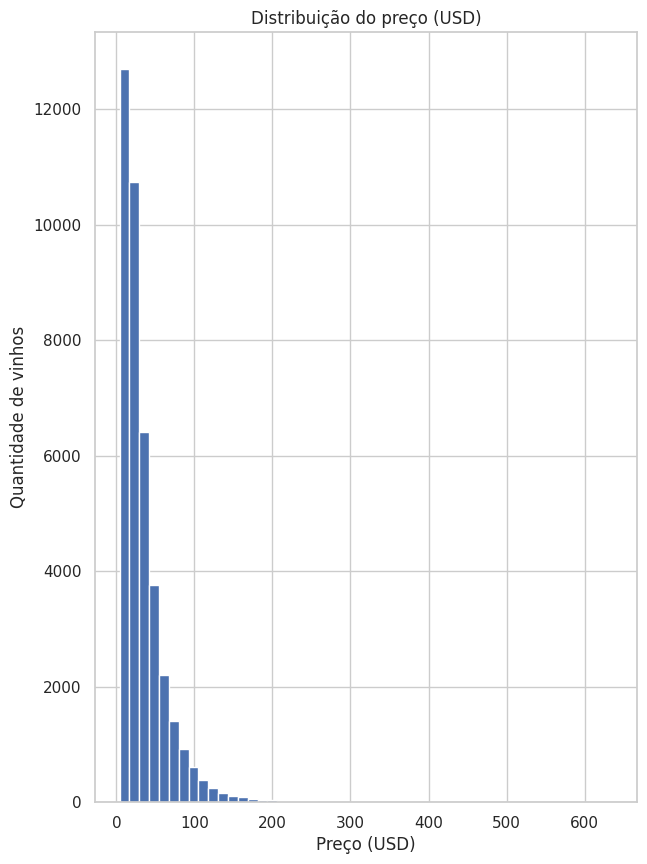

In [ ]:
# Crio um histograma do preço, para entender se a maioria dos vinhos é barato ou caro
plt.figure(figsize=(7,10))  # cria uma figura nova
plt.hist(df["price"], bins=50)  # o comando '.hist()' divide os preços em 50 faixas e conta quantos vinhos caem em cada faixa
plt.title("Distribuição do preço (USD)")  # título do gráfico
plt.xlabel("Preço (USD)")  # nome do eixo x
plt.ylabel("Quantidade de vinhos")  # nome do eixo y
plt.show()  # retorna o gráfico

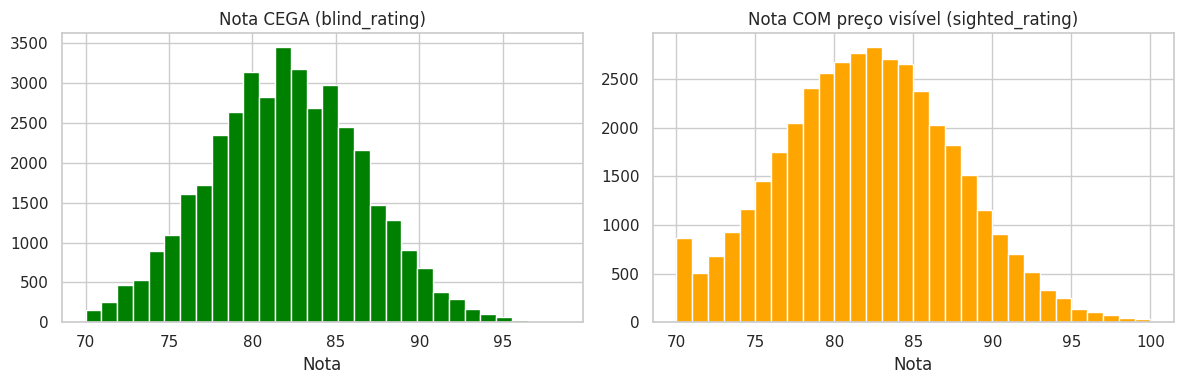

In [ ]:
# Crio histogramas que retornam a comparação das notas dos os testadores que viram o preço com as dos testadores que não viram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # cria 2 gráficos lado a lado

# Primeiro, criando o histograma dos testadores que não viram o preço
axes[0].hist(df["blind_rating"], bins=30, color="green") # separado em 30 faixas
axes[0].set_title("Nota CEGA (blind_rating)")  # título
axes[0].set_xlabel("Nota")  # título do eixo x

# Depois, criando o histograma dos testadores que viram o preço
axes[1].hist(df["sighted_rating"], bins=30, color="orange")  # também separado em 30 faixas
axes[1].set_title("Nota COM preço visível (sighted_rating)")  # título
axes[1].set_xlabel("Nota")  # título eixo x

plt.tight_layout()  # ajusta o espaço para os gráficos não se sobreporem
plt.show() # retorna os gráficos

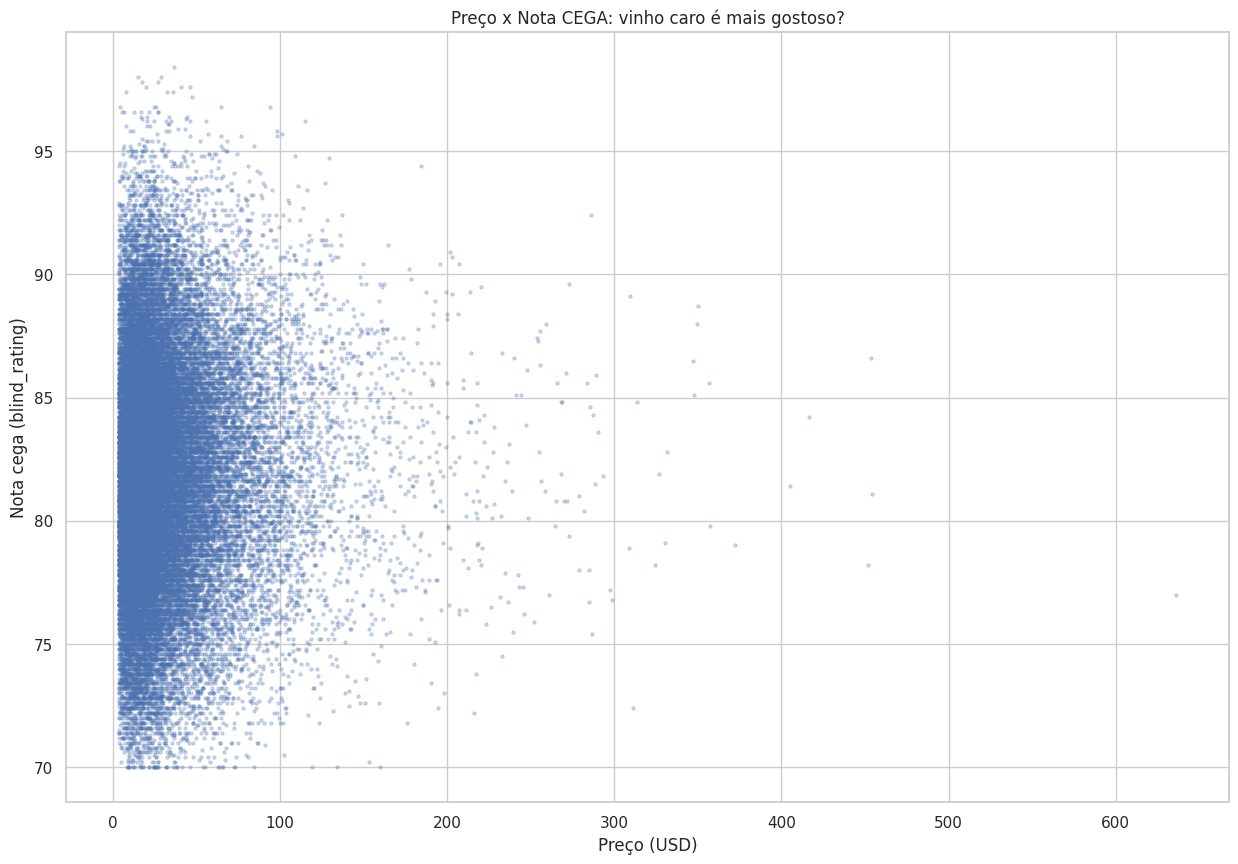

Correlação preço x nota CEGA: 0.03509190773322331
Correlação preço x nota COM preço visível: 0.43158737364468


In [ ]:
# Gráfico de dispersão, que responderá se o preço prevê corretamente o gosto (dispersão do com preço x sem preço)
plt.figure(figsize=(15,10))  # nova figura
plt.scatter(df["price"], df["blind_rating"], alpha=0.25, s=5)  # scatter = pontos; alpha=0.25 deixa transparente
plt.title("Preço x Nota CEGA: vinho caro é mais gostoso?")  # título
plt.xlabel("Preço (USD)")  # eixo x = preço
plt.ylabel("Nota cega (blind_rating)")  # eixo y = nota honesta
plt.show() # retorna o gráfico dde dispersão

# Calcula a correlação (de -1 a 1): -1 = inversamente proporcional, 0 = sem relação, 1 = diretamente proporcional
print("Correlação preço x nota CEGA:", df["price"].corr(df["blind_rating"]))  # o comando '.corr()' mede a força da relação
print("Correlação preço x nota COM preço visível:", df["price"].corr(df["sighted_rating"]))

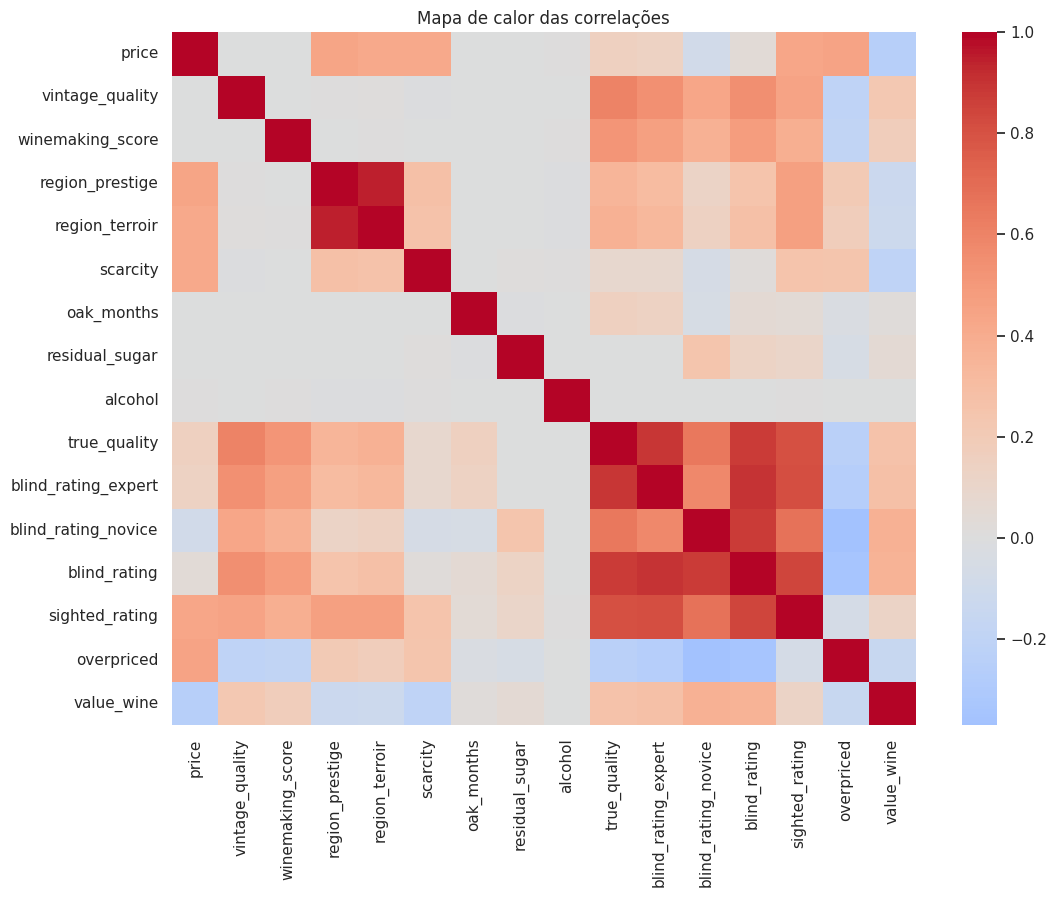

Correlação de cada coluna com blind_rating:
overpriced            -0.346980
alcohol                0.002273
scarcity               0.017916
price                  0.035092
oak_months             0.055308
residual_sugar         0.130582
region_prestige        0.252082
region_terroir         0.273464
value_wine             0.361082
winemaking_score       0.475774
vintage_quality        0.552599
sighted_rating         0.841815
blind_rating_novice    0.874348
true_quality           0.879184
blind_rating_expert    0.903242
blind_rating           1.000000
Name: blind_rating, dtype: float64


In [ ]:
# Mapa de calor (heatmap) das correlações, para verificar o que é relacionado com o que e em qual nível.
colunas_numericas = df.select_dtypes(include="number").columns  # o comando '.select_dtypes' pega só as colunas de números
correlacao = df[colunas_numericas].corr()  # o comando '.corr()' calcula a correlação de cada par de colunas

plt.figure(figsize=(12, 9))  # aumento da figura
sns.heatmap(correlacao, annot=False, cmap="coolwarm", center=0)  # azul = correlação negativa, vermelho = correlação positiva
plt.title("Mapa de calor das correlações")  # título
plt.show()

# Mostra as correlações ordenadas com a nota cega (do menor para o maior)
print("Correlação de cada coluna com blind_rating:")
print(correlacao["blind_rating"].sort_values())

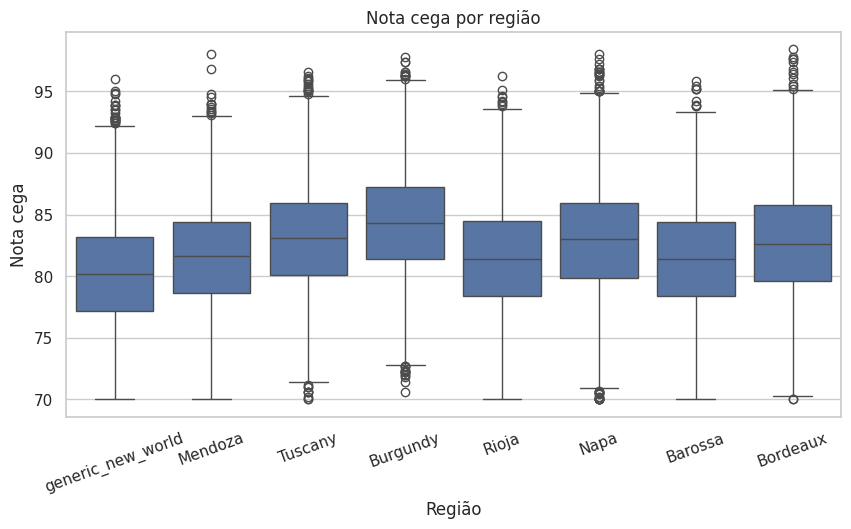

Preço médio por região:
region
Bordeaux             53.088959
Burgundy             52.886748
Napa                 42.790205
Tuscany              34.940449
Barossa              28.768758
Rioja                27.750468
Mendoza              23.286904
generic_new_world    15.389021
Name: price, dtype: float64


In [ ]:
# Criando um boxplot, para verificar se a nota cega se altera dependendo da região
plt.figure(figsize=(10, 5))  # figura mais larga (são 8 regiões)
sns.boxplot(data=df, x="region", y="blind_rating")  # boxplot mostra mediana, quartis e outliers por grupo
plt.title("Nota cega por região")  # título
plt.xlabel("Região")  # eixo x
plt.ylabel("Nota cega")  # eixo y
plt.xticks(rotation=20)  # gira os nomes das regiões para não se sobreporem
plt.show()

# Retornando o preço médio por região, para verificar qual região cobra mais caro
print("Preço médio por região:")
# o comando '.groupby('region')' agrupa por região; '['price'].mean()' tira a média do preço; '.sort_values()' ordena do maior para o menor
print(df.groupby("region")["price"].mean().sort_values(ascending=False))

                price  blind_rating  sighted_rating
overpriced                                         
0           27.428393     82.714692       82.189782
1           64.017866     78.457212       81.273937


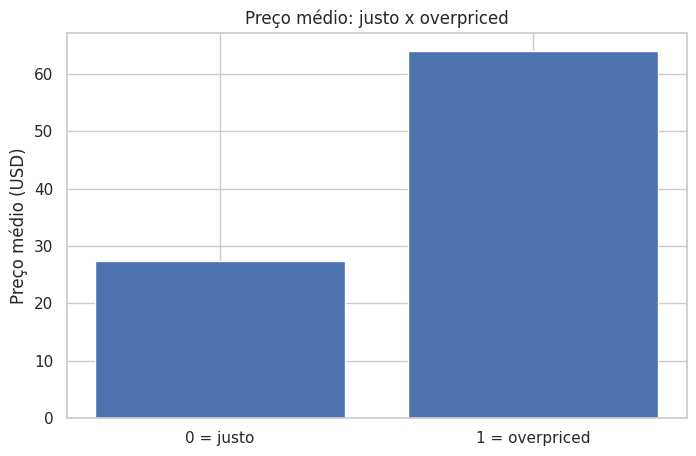

In [ ]:
# Agora, com um gráfico de barras simples, é comparada a média do preço do vinho superfaturado do justo, para verificar se o rótulo engana de fato
# Agrupa pela coluna overpriced (0 = justo, 1 = caro e mediano), e tira a média de preço, nota cega e nota com preço
print(df.groupby("overpriced")[["price", "blind_rating", "sighted_rating"]].mean())

# Criação do gráfico de barras, comparando os preços
medias = df.groupby("overpriced")["price"].mean()  # média de preço por grupo
plt.figure()  # nova figura
plt.bar(["0 = justo", "1 = overpriced"], medias.values)  # o comando '.bar()' faz um gráfico de barras
plt.title("Preço médio: justo x overpriced")  # título
plt.ylabel("Preço médio (USD)")  # ttítulo do eixo y
plt.show() # é retornado o gráfico

In [ ]:
# 5.1 Separando X (características = pergunta) e y (resposta = overpriced)
# Primeiro, o X (características) é separado do y (rótulos)
colunas_num = ["price", "vintage_quality", "winemaking_score", "region_prestige",
               "region_terroir", "scarcity", "oak_months", "residual_sugar",
               "alcohol", "true_quality", "blind_rating_expert",
               "blind_rating_novice", "blind_rating", "sighted_rating"]  # todas as numéricas úteis
colunas_cat = ["region", "grape"]  # as duas linhas de texto

X = df[colunas_num + colunas_cat]  # X = tudo que o modelo pode olhar
y = df["overpriced"]  # y = a resposta a ser prevista (0 ou 1)

print("Tamanho de X:", X.shape)  # mostra quantas linhas e colunas o modelo vai usar
print("Tamanho de y:", y.shape)  # y tem o mesmo número de linhas
print("\nProporção das classes:")  # retorna o desbalanceamento
print(y.value_counts(normalize=True))

Tamanho de X: (40000, 16)
Tamanho de y: (40000,)

Proporção das classes:
overpriced
0    0.834825
1    0.165175
Name: proportion, dtype: float64


In [ ]:
# 5.2 Tratamento de colunas categóricas (One-Hot Encoding) e preenchimento de nulos
X_encoded = pd.get_dummies(X, columns=colunas_cat, drop_first=True)
X_encoded = X_encoded.fillna(X_encoded.median())

# 5.3 Divisão em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 5.4 Dicionário com os modelos
models = {
    "SVM (Linear)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='linear', random_state=42))]),
    "SVM (RBF)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', random_state=42))]),
    "SVM (Polinomial)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='poly', degree=3, random_state=42))]),
    "SVM (Sigmoide)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='sigmoid', random_state=42))]),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Floresta Aleatória": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

SVM (Linear)
Acurácia Média (CV): 0.8938
Acurácia no Teste: 0.8946

              precision    recall  f1-score   support

           0       0.92      0.96      0.94      6679
           1       0.72      0.58      0.65      1321

    accuracy                           0.89      8000
   macro avg       0.82      0.77      0.79      8000
weighted avg       0.89      0.89      0.89      8000



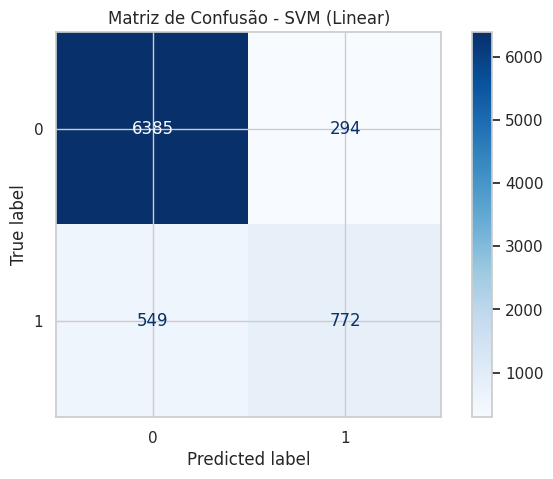

--------------------------------------------------
SVM (RBF)
Acurácia Média (CV): 0.9668
Acurácia no Teste: 0.9684

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      6679
           1       0.93      0.87      0.90      1321

    accuracy                           0.97      8000
   macro avg       0.95      0.93      0.94      8000
weighted avg       0.97      0.97      0.97      8000



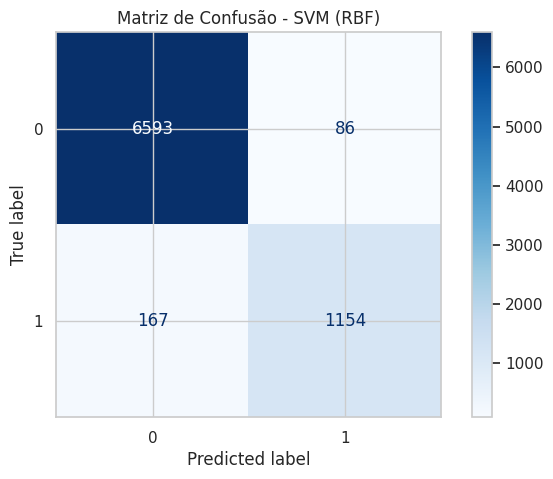

--------------------------------------------------
SVM (Polinomial)
Acurácia Média (CV): 0.9396
Acurácia no Teste: 0.9413

              precision    recall  f1-score   support

           0       0.95      0.98      0.97      6679
           1       0.90      0.73      0.80      1321

    accuracy                           0.94      8000
   macro avg       0.92      0.86      0.88      8000
weighted avg       0.94      0.94      0.94      8000



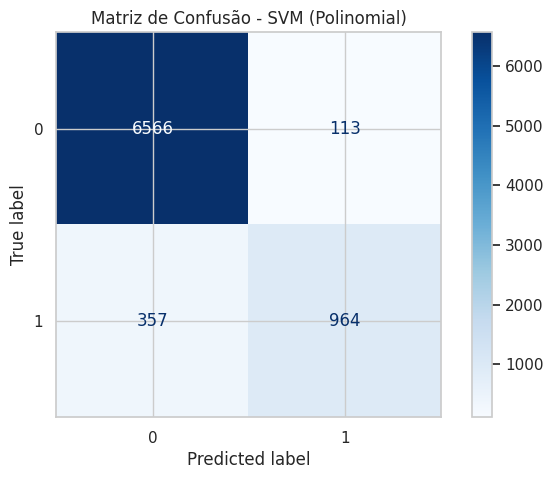

--------------------------------------------------
SVM (Sigmoide)
Acurácia Média (CV): 0.7992
Acurácia no Teste: 0.7959

              precision    recall  f1-score   support

           0       0.88      0.87      0.88      6679
           1       0.39      0.40      0.39      1321

    accuracy                           0.80      8000
   macro avg       0.63      0.64      0.64      8000
weighted avg       0.80      0.80      0.80      8000



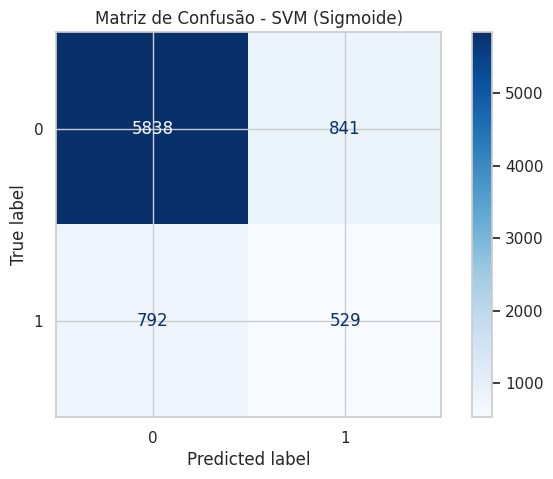

--------------------------------------------------
Árvore de Decisão
Acurácia Média (CV): 1.0000
Acurácia no Teste: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6679
           1       1.00      1.00      1.00      1321

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000



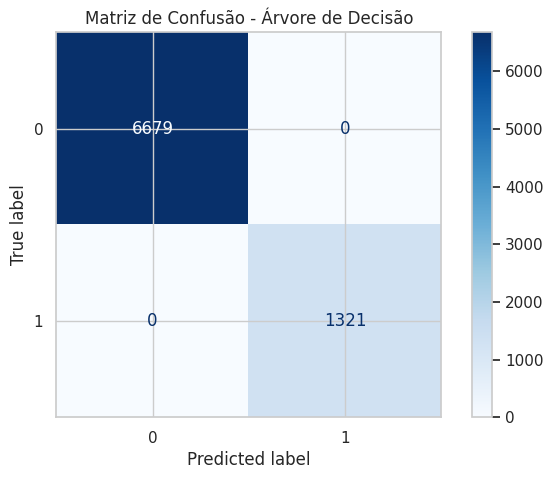

--------------------------------------------------
Floresta Aleatória
Acurácia Média (CV): 1.0000
Acurácia no Teste: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6679
           1       1.00      1.00      1.00      1321

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000



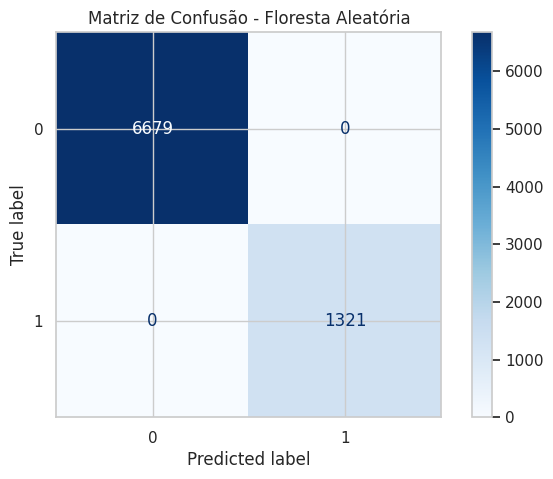

--------------------------------------------------
Gradient Boosting
Acurácia Média (CV): 1.0000
Acurácia no Teste: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6679
           1       1.00      1.00      1.00      1321

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000



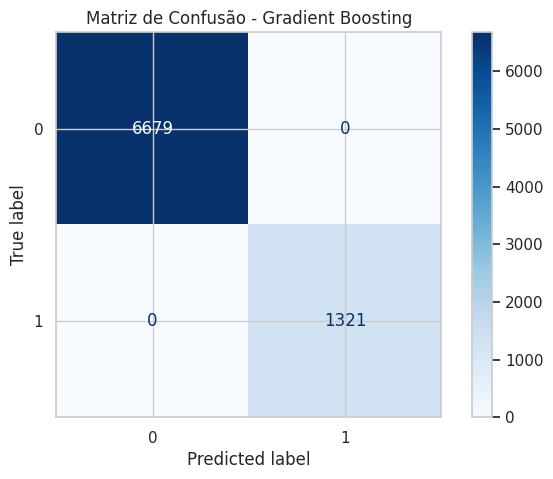

--------------------------------------------------


In [ ]:
# 5.5 Treinamento e avaliação de todos os modelos
results = {}

for name, model in models.items():
    # Validação cruzada (5 folds)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

    # Treino e Predição
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'Acurácia Média (CV)': cv_scores.mean(),
        'Acurácia (Teste)': test_acc
    }

    print(f"{name}")
    print(f"Acurácia Média (CV): {cv_scores.mean():.4f}")
    print(f"Acurácia no Teste: {test_acc:.4f}\n")
    print(classification_report(y_test, y_pred))

    # Matriz de Confusão
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Matriz de Confusão - {name}")
    plt.show()
    print("-" * 50)

In [ ]:
# Criando e transpondo o DataFrame
df_resumo = pd.DataFrame(results).T

# 1. Identificação dinâmica dos nomes das colunas (Português ou Inglês)
col_cv = 'CV Mean Accuracy' if 'CV Mean Accuracy' in df_resumo.columns else (
    'Acurácia Média (CV)' if 'Acurácia Média (CV)' in df_resumo.columns else 'Acurácia (CV)'
)
col_test = 'Test Accuracy' if 'Test Accuracy' in df_resumo.columns else 'Acurácia (Teste)'

# 2. Ordenação segura da tabela pelo conjunto de teste
if col_test in df_resumo.columns:
    df_resumo = df_resumo.sort_values(by=col_test, ascending=False)
else:
    df_resumo = df_resumo.sort_values(by=df_resumo.columns[0], ascending=False)

print("\nResumo Comparativo dos Modelos:")
print(df_resumo)

# 3. Extração dinâmica das métricas do melhor modelo
melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, col_cv]
acc_test = df_resumo.loc[melhor_modelo, col_test]

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")
if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")


Resumo Comparativo dos Modelos:
                    Acurácia Média (CV)  Acurácia (Teste)
Gradient Boosting              0.999969          1.000000
Floresta Aleatória             0.999969          1.000000
Árvore de Decisão              0.999969          1.000000
SVM (RBF)                      0.966781          0.968375
SVM (Polinomial)               0.939594          0.941250
SVM (Linear)                   0.893813          0.894625
SVM (Sigmoide)                 0.799188          0.795875

DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: Gradient Boosting
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.


---
# Eleições de 1936

In [ ]:
import os
from enum import Enum, auto
from abc import ABC
from google.colab import drive
import numpy as np
from numpy import ndarray, uint8, uint16, uint32, dtype
from numpy.typing import NDArray, DTypeLike
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")
!pip install openpyxl

In [ ]:
# 2. Define o caminho absoluto exato da planilha de dados no Google Colab
file_path: str = '/content/LitDigestFull.xlsx'

# 3. Dicionário de metadados com anotação de tipos
tables_indexes_sizes: dict[str, list[tuple[int, int]]] = {
    '1924': [
        (1, 1), # _electoral_votes
        (2, 8), # __candidates
        (13, 6), # __same_voters_1920
        (19, 1), # _total_per_state
        (22, 22), # _results
    ],
    '1928': [
        (1, 1), # _electoral_votes
        (2, 1), # __hoover
        (3, 6), # __hoover_voters_1924
        (10, 1), # __smith
        (11, 6), # __smith_voters_1924
        (20, 3), # __minor_candidates
        (23, 1), # __total_per_state
        (26, 19), # _results
    ],
    '1932': [
        (1, 1), # _electoral_votes
        (2, 1), # __hoover
        (3, 4), # __hoover_voters_1928
        (9, 1), # __roosevelt
        (10, 4), # __roosevelt_voters_1928
        (16, 7), # _minor_candidates
        (24, 1), # _total_per_state
        (28, 16), # _results
    ],
    '1936': [
        (1, 1), # _electoral_votes
        (2, 1), # __landon
        (3, 6), # __landon_voters_1932
        (10, 1), # __roosevelt
        (11, 6), # __roosevelt_voters_1932
        (18, 1), # __lemke
        (19, 6), # __lemke_voters_1932
        (26, 6), # __minor_candidates
        (32, 1), # _total_per_state
        (35, 19), # _results
    ]
}

discarded_lines: list[int] = [8, -2] # (Distrito de Columbia e Estados desconhecidos)

class StatesEnum(Enum):
    ALABAMA = auto(), 'AL'
    ARIZONA = auto(), 'AZ'
    ARKANSAS = auto(), 'AR'
    CALIFORNIA = auto(), 'CA'
    COLORADO = auto(), 'CO'
    CONNECTICUT = auto(), 'CT'
    DELAWARE = auto(), 'DE'
    FLORIDA = auto(), 'FL'
    GEORGIA = auto(), 'GA'
    IDAHO = auto(), 'ID'
    ILLINOIS = auto(), 'IL'
    INDIANA = auto(), 'IN'
    IOWA = auto(), 'IA'
    KANSAS = auto(), 'KS'
    KENTUCKY = auto(), 'KY'
    LOUISIANA = auto(), 'LA'
    MAINE = auto(), 'ME'
    MARYLAND = auto(), 'MD'
    MASSACHUSETTS = auto(), 'MA'
    MICHIGAN = auto(), 'MI'
    MINNESOTA = auto(), 'MN'
    MISSISSIPPI = auto(), 'MS'
    MISSOURI = auto(), 'MO'
    MONTANA = auto(), 'MT'
    NEBRASKA = auto(), 'NE'
    NEVADA = auto(), 'NV'
    NEW_HAMPSHIRE = auto(), 'NH'
    NEW_JERSEY = auto(), 'NJ'
    NEW_MEXICO = auto(), 'NM'
    NEW_YORK = auto(), 'NY'
    NORTH_CAROLINA = auto(), 'NC'
    NORTH_DAKOTA = auto(), 'ND'
    OHIO = auto(), 'OH'
    OKLAHOMA = auto(), 'OK'
    OREGON = auto(), 'OR'
    PENNSYLVANIA = auto(), 'PA'
    RHODE_ISLAND = auto(), 'RI'
    SOUTH_CAROLINA = auto(), 'SC'
    SOUTH_DAKOTA = auto(), 'SD'
    TENNESSEE = auto(), 'TN'
    TEXAS = auto(), 'TX'
    UTAH = auto(), 'UT'
    VERMONT = auto(), 'VT'
    VIRGINIA = auto(), 'VA'
    WASHINGTON = auto(), 'WA'
    WEST_VIRGINIA = auto(), 'WV'
    WISCONSIN = auto(), 'WI'
    WYOMING = auto(), 'WY'

def read_path(path: str) -> dict[str, pd.DataFrame]:
    try:
        excel_data = pd.read_excel(
            path,
            sheet_name=list(tables_indexes_sizes.keys()),
        )
    except (FileNotFoundError, ValueError, OSError) as error:
        print(f"\nArquivo inválido ou não encontrado: {path} ({error})\n")
        return {}
    else:
        return excel_data

# Executa a leitura dos dados
raw_tables = read_path(file_path)
print("Tabelas carregadas com sucesso! Abas lidas:", list(raw_tables.keys()))


Arquivo inválido ou não encontrado: /content/LitDigestFull.xlsx ([Errno 2] No such file or directory: '/content/LitDigestFull.xlsx')

Tabelas carregadas com sucesso! Abas lidas: []


In [ ]:
# Versão 1: Usando NDArray da biblioteca numpy.typing (recomendado e mais limpo)
def create_columns_index(first: int, size: int) -> NDArray[uint8]:
    # Gera a sequência contínua de índices numéricos de colunas em baixo nível
    return np.array(range(size), dtype=uint8) + first

# Fatia a aba do Excel em sub-tabelas utilizando o método nativo em C 'take()' do Pandas
def tables_to_df(sheet: DataFrame, indexes_sizes: list[tuple[int, int]]) -> list[DataFrame]:
    return [
        # Aplica a extração de alta performance para cada tupla (índice, tamanho) da aba
        sheet.take(indices=create_columns_index(index, size), axis='columns')
        for index, size in indexes_sizes
    ]

In [ ]:
# 1. Carrega todas as abas do Excel para a memória em um dicionário de DataFrames brutos
sheets: dict[str, DataFrame] = read_path(file_path)

# 2. Executa a dictionary comprehension para fatiar todas as sub-tabelas de cada ano em lote,
# gerando a estrutura final higienizada em 'raw_tables'

raw_tables: dict[str, list[DataFrame]] = {
    name: tables_to_df(sheets[name], indexes)
    for name, indexes in tables_indexes_sizes.items()
}

del tables_indexes_sizes, sheets

In [ ]:
class Votes(ABC):
    __slots__ = ('_results', '_electoral_votes', '_total_per_state')

    _results: DataFrame
    _electoral_votes: NDArray[np.uint8]
    _total_per_state: NDArray[np.uint32]

    def _clean_lines(self, df: DataFrame) -> DataFrame:
        # Método interno de higienização: Remove linhas completamente vazias
        return df.dropna(axis='index', how='all')

    def _series_to_nparray(self, df: DataFrame, dtype: DTypeLike = np.uint16) -> NDArray:
        df = self._clean_lines(df)
        return np.asarray(df[df.columns[0]].to_numpy(), dtype)

    def _get_totals(self, df: DataFrame) -> NDArray[np.uint32]:
        return df.values[-1]

    def get_electoral_votes(self) -> NDArray[np.uint8]:
        return self._electoral_votes[:-1]

    def get_total_per_state(self) -> NDArray[np.uint32]:
        return self._total_per_state[:-1]

    def get_results(self) -> DataFrame:
        return self._results[:-1]

    def get_total_results(self) -> NDArray[np.uint32]:
        return self._get_totals(self._results)

    def _set_header_from(self, df: DataFrame, line_index: int = 0) -> DataFrame:
        df.columns = df.values[line_index]
        return df.drop(index=line_index)

    def _discard_lines(self, source: DataFrame, indexes: list[int]) -> DataFrame:
        return source.drop(index=[source.index[index] for index in indexes])

    def _prepare_dataframe(self, df: DataFrame, header_index: int = -1, discard_indexes: list[int] = [], clean_lines: bool = True) -> DataFrame:
        if clean_lines:
            df = self._clean_lines(df)
        if header_index != -1:
            df = self._set_header_from(df, header_index)
        if not len(discard_indexes) == 0:
            df = self._discard_lines(df, discard_indexes)
        return df

    def _prepare_nparray(self, df: DataFrame, header_index: int = -1, discard_indexes: list[int] = [], clean_lines: bool = True, dtype: DTypeLike = np.uint32) -> NDArray:
        return self._series_to_nparray(self._prepare_dataframe(df, header_index, discard_indexes, clean_lines), dtype)

In [ ]:
class Votes1924(Votes):
# __slots__ específico para os atributos privados exclusivos da eleição de 1924
    __slots__ = ('__candidates', '__same_voters_1920')
    __candidates: DataFrame
    __same_voters_1920: DataFrame

    def __init__(self, electoral_votes: DataFrame, candidates: DataFrame, same_voters_1920: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Construtor da classe para o ano de 1924: Recebe as sub-tabelas fatiadas e inicializa os atributos tratados.
# Remove a última coluna da sub-tabela de candidatos (geralmente uma coluna duplicada de total)

        self.__candidates = self._prepare_dataframe(candidates, discard_indexes=discarded_lines)
# Atribui a sub-tabela do histórico do voto cruzado da eleição de 1920
        self.__same_voters_1920 = self._prepare_dataframe(same_voters_1920, discard_indexes=discarded_lines)
# Converte e armazena os votos eleitorais usando uint8 (economia de memória)
        self._electoral_votes = self._prepare_nparray(electoral_votes, discard_indexes=[discarded_lines[0]], dtype=uint16).astype(uint16)
# Atribui o DataFrame do total por estado
        self._total_per_state = self._prepare_nparray(total_per_state, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Atribui o DataFrame com os resultados reais de 1924 (Wikipedia)
        self._results = self._prepare_dataframe(results)

    def get_candidates(self) -> DataFrame:
 # Getter público: Retorna as intenções de voto dos candidatos de 1924 por estado (sem a linha de total).
        return self.__candidates[:-1]

    def get_total_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: Retorna o vetor com o somatório nacional de votos de cada candidato em 1924.
        return self._get_totals(self.__candidates)

    def get_same_voters_1920(self) -> DataFrame:
# Getter público: Retorna o histórico de como os eleitores de 1924 votaram em 1920 por estado (sem a linha de total).
        return self.__same_voters_1920[:-1]

    def get_total_same_voters_1920(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: Retorna o vetor com o somatório nacional do histórico de voto de 1920.
        return self._get_totals(self.__same_voters_1920)

In [ ]:
# Classe derivada concreta referente ao ano eleitoral de 1928 (Hoover x Smith)
class Votes1928(Votes):
# __slots__ limita dinamicamente os atributos da classe aos declarados, reduzindo o consumo de memória RAM
    __slots__ = ('__hoover', '__hoover_voters_1924', '__smith', '__smith_voters_1924', '__minor_candidates')
    __hoover: ndarray[tuple[int], dtype[uint32]]
    __hoover_voters_1924: DataFrame
    __smith: ndarray[tuple[int], dtype[uint32]]
    __smith_voters_1924: DataFrame
    __minor_candidates: DataFrame

# Construtor da classe de 1928: recebe os DataFrames fatiados e os converte para estruturas otimizadas
    def __init__(self, electoral_votes: DataFrame, hoover: DataFrame, hoover_voters_1924: DataFrame, smith: DataFrame, smith_voters_1924: DataFrame, minor_candidates: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Converte a coluna de votos de Herbert Hoover em ndarray NumPy tipado (uint32)
        self.__hoover = self._prepare_nparray(hoover, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1924 dos eleitores de Hoover
        self.__hoover_voters_1924 = self._prepare_dataframe(hoover_voters_1924, header_index=0, discard_indexes=discarded_lines)
# Converte a coluna de votos de Alfred Smith em ndarray NumPy tipado (uint32)
        self.__smith = self._prepare_nparray(smith, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1924 dos eleitores de Smith
        self.__smith_voters_1924 = self._prepare_dataframe(smith_voters_1924, header_index=0, discard_indexes=discarded_lines)
# Armazena o DataFrame dos candidatos minoritários
        self.__minor_candidates = self._prepare_dataframe(minor_candidates, header_index=0, discard_indexes=discarded_lines)
# Converte os votos do Colégio Eleitoral em array NumPy tipado (uint8)
        self._electoral_votes = self._prepare_nparray(electoral_votes, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint16).astype(uint16)
# Converte os totais por estado em array NumPy tipado (uint32)
        self._total_per_state = self._prepare_nparray(total_per_state, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com os resultados reais das urnas de 1928
        self._results = self._prepare_dataframe(results)

    def get_hoover(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Hoover por estado (excluindo a linha final de totalizador)
        return self.__hoover[:-1]

    def get_total_hoover(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Hoover
        return self.__hoover[-1]

    def get_hoover_voters_1924(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1924 dos eleitores de Hoover por estado (sem totalizador)
        return self.__hoover_voters_1924[:-1]

    def get_total_hoover_voters_1924(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1924 dos eleitores de Hoover
        return self._get_totals(self.__hoover_voters_1924)

    def get_smith(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Smith por estado (excluindo a linha final de totalizador)
        return self.__smith[:-1]

    def get_total_smith(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Smith
        return self.__smith[-1]

    def get_smith_voters_1924(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1924 dos eleitores de Smith por estado (sem totalizador)
        return self.__smith_voters_1924[:-1]

    def get_total_smith_voters_1924(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1924 dos eleitores de Smith
        return self._get_totals(self.__smith_voters_1924)

    def get_minor_candidates(self) -> DataFrame:
# Getter público: retorna as votações dos candidatos minoritários por estado (sem totalizador)
        return self.__minor_candidates[:-1]

    def get_total_minor_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional dos candidatos minoritários
        return self._get_totals(self.__minor_candidates)

In [ ]:
# Classe derivada concreta referente ao ano eleitoral de 1932 (Hoover x Roosevelt)
class Votes1932(Votes):
# __slots__ limita dinamicamente os atributos da classe aos declarados, reduzindo o consumo de memória RAM
    __slots__ = ('__hoover', '__hoover_voters_1928', '__roosevelt', '__roosevelt_voters_1928', '__minor_candidates')
    __hoover: ndarray[tuple[int], dtype[uint32]]
    __hoover_voters_1928: DataFrame
    __roosevelt: ndarray[tuple[int], dtype[uint32]]
    __roosevelt_voters_1928: DataFrame
    __minor_candidates: DataFrame

# Construtor da classe de 1932: recebe os DataFrames fatiados e os converte para estruturas otimizadas
    def __init__(self, electoral_votes: DataFrame, hoover: DataFrame, hoover_voters_1928: DataFrame, roosevelt: DataFrame, roosevelt_voters_1928: DataFrame, minor_candidates: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Converte a coluna de votos de Herbert Hoover em ndarray NumPy tipado (uint32)
        self.__hoover = self._prepare_nparray(hoover, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1928 dos eleitores de Hoover
        self.__hoover_voters_1928 = self._prepare_dataframe(hoover_voters_1928, header_index=0, discard_indexes=discarded_lines)
# Converte a coluna de votos de Franklin D. Roosevelt em ndarray NumPy tipado (uint32)
        self.__roosevelt = self._prepare_nparray(roosevelt, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1928 dos eleitores de Roosevelt
        self.__roosevelt_voters_1928 = self._prepare_dataframe(roosevelt_voters_1928, header_index=0, discard_indexes=discarded_lines)
# Armazena o DataFrame dos candidatos minoritários
        self.__minor_candidates = self._prepare_dataframe(minor_candidates, header_index=0, discard_indexes=discarded_lines)
# Converte os votos do Colégio Eleitoral em array NumPy tipado (uint8)
        self._electoral_votes = self._prepare_nparray(electoral_votes, header_index=0, discard_indexes=discarded_lines, dtype=uint16).astype(uint16)
# Converte os totais por estado em array NumPy tipado (uint32)
        self._total_per_state = self._prepare_nparray(total_per_state, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com os resultados reais das urnas de 1932
        self._results = self._prepare_dataframe(results)

    def get_hoover(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Hoover por estado (excluindo a linha final de totalizador)
        return self.__hoover[:-1]

    def get_total_hoover(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Hoover
        return self.__hoover[-1]

    def get_hoover_voters_1928(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1928 dos eleitores de Hoover por estado (sem totalizador)
        return self.__hoover_voters_1928[:-1]

    def get_total_hoover_voters_1928(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1928 dos eleitores de Hoover
        return self._get_totals(self.__hoover_voters_1928)

    def get_roosevelt(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Roosevelt por estado (excluindo a linha final de totalizador)
        return self.__roosevelt[:-1]

    def get_total_roosevelt(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Roosevelt
        return self.__roosevelt[-1]

    def get_roosevelt_voters_1928(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1928 dos eleitores de Roosevelt por estado (sem totalizador)
        return self.__roosevelt_voters_1928[:-1]

    def get_total_roosevelt_voters_1928(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1928 dos eleitores de Roosevelt
        return self._get_totals(self.__roosevelt_voters_1928)

    def get_minor_candidates(self) -> DataFrame:
# Getter público: retorna as votações dos candidatos minoritários por estado (sem totalizador)
        return self.__minor_candidates[:-1]

    def get_total_minor_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional dos candidatos minoritários
        return self._get_totals(self.__minor_candidates)

In [ ]:
# Classe derivada concreta referente ao ano eleitoral decisivo de 1936 (Landon x Roosevelt x Lemke)
class Votes1936(Votes):
# __slots__ limita dinamicamente os atributos da classe aos declarados, reduzindo o consumo de memória RAM
    __slots__ = ('__landon', '__landon_voters_1932', '__roosevelt', '__roosevelt_voters_1932', '__lemke', '__lemke_voters_1932', '__minor_candidates')
    __landon: ndarray[tuple[int], dtype[uint32]]
    __landon_voters_1932: DataFrame
    __roosevelt: ndarray[tuple[int], dtype[uint32]]
    __roosevelt_voters_1932: DataFrame
    __lemke: ndarray[tuple[int], dtype[uint32]]
    __lemke_voters_1932: DataFrame
    __minor_candidates: DataFrame

# Converte a coluna de votos de Alf Landon em ndarray NumPy tipado (uint32)
    def __init__(self, electoral_votes: DataFrame, landon: DataFrame, landon_voters_1932: DataFrame, roosevelt: DataFrame, roosevelt_voters_1932: DataFrame, lemke: DataFrame, lemke_voters_1932: DataFrame, minor_candidates: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Armazena a sub-tabela com o histórico do voto de 1932 dos eleitores de Landon
        self.__landon = self._prepare_nparray(landon, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
# Converte a coluna de votos de Franklin D. Roosevelt em ndarray NumPy tipado (uint32)
        self.__landon_voters_1932 = self._prepare_dataframe(landon_voters_1932, header_index=0, discard_indexes=discarded_lines[1:])
# Armazena a sub-tabela com o histórico do voto de 1932 dos eleitores de Roosevelt
        self.__roosevelt = self._prepare_nparray(roosevelt, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
        self.__roosevelt_voters_1932 = self._prepare_dataframe(roosevelt_voters_1932, header_index=0, discard_indexes=discarded_lines[1:])
# Converte a coluna de votos de William Lemke (terceiro partido) em ndarray NumPy tipado (uint32)
        self.__lemke = self._prepare_nparray(lemke, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1932 dos eleitores de Lemke
        self.__lemke_voters_1932 = self._prepare_dataframe(lemke_voters_1932, header_index=0, discard_indexes=discarded_lines[1:])
# Armazena o DataFrame dos candidatos minoritários
        self.__minor_candidates = self._prepare_dataframe(minor_candidates, header_index=0, discard_indexes=discarded_lines[1:])
# Converte os votos do Colégio Eleitoral em array NumPy tipado (uint8)
        self._electoral_votes = self._prepare_nparray(electoral_votes, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint16).astype(uint16)
# Converte os totais por estado em array NumPy tipado (uint32)
        self._total_per_state = self._prepare_nparray(total_per_state, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
# Armazena a sub-tabela com os resultados reais das urnas de 1936
        self._results = self._prepare_dataframe(results)

    def get_landon(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Landon por estado (excluindo a linha final de totalizador)
        return self.__landon[:-1]

    def get_total_landon(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Landon
        return self.__landon[-1]

    def get_landon_voters_1932(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1932 dos eleitores de Landon por estado (sem totalizador)
        return self.__landon_voters_1932[:-1]

    def get_total_landon_voters_1932(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1932 dos eleitores de Landon
        return self._get_totals(self.__landon_voters_1932)

    def get_roosevelt(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Roosevelt por estado (excluindo a linha final de totalizador)
        return self.__roosevelt[:-1]

    def get_total_roosevelt(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Roosevelt
        return self.__roosevelt[-1]

    def get_roosevelt_voters_1932(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1932 dos eleitores de Roosevelt por estado (sem totalizador)
        return self.__roosevelt_voters_1932[:-1]

    def get_total_roosevelt_voters_1932(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1932 dos eleitores de Roosevelt
        return self._get_totals(self.__roosevelt_voters_1932)

    def get_lemke(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Lemke por estado (excluindo a linha final de totalizador)
        return self.__lemke[:-1]

    def get_total_lemke(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Lemke
        return self.__lemke[-1]

    def get_lemke_voters_1932(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1932 dos eleitores de Lemke por estado (sem totalizador)
        return self.__lemke_voters_1932[:-1]

    def get_total_lemke_voters_1932(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1932 dos eleitores de Lemke
        return self._get_totals(self.__lemke_voters_1932)

    def get_minor_candidates(self) -> DataFrame:
# Getter público: retorna as votações dos candidatos minoritários por estado (sem totalizador)
        return self.__minor_candidates[:-1]

    def get_total_minor_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional dos candidatos minoritários
        return self._get_totals(self.__minor_candidates)

In [ ]:
# Instancia o objeto 'votes1924' da classe Votes1924 utilizando o operador de desempacotamento posicional (*),
# repassando a lista de sub-tabelas do dicionário 'raw_tables['1924']' diretamente para o construtor __init__
votes1924: Votes1924 = Votes1924(*raw_tables['1924'])

# Instancia o objeto 'votes1928' da classe Votes1928 via desempacotamento posicional (*raw_tables['1928']),
# alimentando os parâmetros de candidatos e votação cruzada de 1924 com tipagem estrita
votes1928: Votes1928 = Votes1928(*raw_tables['1928'])

# Instancia o objeto 'votes1932' da classe Votes1932 via desempacotamento posicional (*raw_tables['1932']),
# mapeando as sub-tabelas de Hoover e Roosevelt e o histórico de 1928 para a estrutura estática
votes1932: Votes1932 = Votes1932(*raw_tables['1932'])

# Instancia o objeto 'votes1936' da classe Votes1936 via desempacotamento posicional (*raw_tables['1936']),
# inicializando o modelo trifurcado (Landon, Roosevelt e Lemke) com os dados das urnas e pesquisas
votes1936: Votes1936 = Votes1936(*raw_tables['1936'])

# Apaga explicitamente do ambiente Python o dicionário 'raw_tables' contendo a lista de DataFrames intermediários,
# acionando o Garbage Collector e liberando memória RAM após a conversão dos dados para os objetos tipados
del raw_tables

In [ ]:
# Puxa o DataFrame com as contagens de votos previstos na pesquisa de 1924
cand_df_1924 = votes1924.get_candidates()

# Extrai os vetores de votos de Coolidge e Davis
# Coolidge (Republicano - Coluna 0)
# Davis (Democrata - Coluna 1)
coolidge = cand_df_1924[cand_df_1924.columns[0]]
davis = cand_df_1924[cand_df_1924.columns[1]]

# Proporção Prevista (Two-Party Share da Pesquisa)
# Calcula a porcentagem do candidato Republicano em relação ao total bipartidário (0% a 100%)
# Isola os dois partidos para o deslocamento eleitoral
# Usamos um candidato como referência, pois os dois representam 100%
expected_proportions_1924 = coolidge / (coolidge + davis) * 100
print("Proporção Prevista (Pesquisa):")
print(expected_proportions_1924)

Proporção Prevista (Pesquisa):
0     32.066005
1     68.057989
2     34.167254
3     88.185266
4     80.318349
5     86.924825
6     68.125439
7     76.139497
9     24.461416
10    79.428032
11    83.595097
12    73.651074
13    81.854137
14    77.924123
15    49.845907
16    40.704486
17    85.692432
18    57.516152
19    88.516211
20    89.416612
21    86.804056
22    17.543054
23    60.045627
24    80.849936
25    70.114943
26    77.946768
27    82.890099
28    84.216588
29    61.951849
30    82.103776
31    38.478646
32    83.725156
33    79.253093
34    54.494297
35    77.887371
36    82.470408
37    88.318293
38    11.129873
39    81.951329
40    43.168043
41    38.566426
42    72.111408
43    90.906224
44    37.492420
45    84.732030
46    56.084542
47    85.572097
48    82.135129
dtype: float64


In [ ]:
# Puxa o DataFrame oficial dos resultados eleitorais de 1924
results = votes1924.get_results()

# Extrai a contagem real de votos das urnas para Coolidge e Davis
coolidge_expected = results[results.columns[1]]
davis_expected = results[results.columns[4]]

# Proporção Esperada (Urnas Reais em %)
# Ao multiplicar por 100 estou passando para porcentagem
# Usa os dados reais da eleição
actual_proportions_1924 = (coolidge_expected / ( coolidge_expected + davis_expected)) * 100
print("\nProporção Esperada (Urnas):")
print(actual_proportions_1924)


Proporção Esperada (Urnas):
0     28.489406
1     53.771740
2     32.358267
3     87.420299
4     72.176222
5     69.093367
6     61.058845
7     33.039605
8     19.739414
9     74.232751
10    71.581730
11    58.817840
12    76.779224
13    72.283374
14    51.557918
15    20.926642
16    76.738875
17    52.309605
18    71.469166
19    85.164510
20    88.270131
21     7.794949
22    53.100663
23    68.682545
24    61.422020
25    65.549207
26    63.279966
27    69.396498
28    53.002798
29    65.685814
30    40.282297
31    87.261580
32    71.107449
33    46.934279
34    67.840490
35    77.401110
36    62.055951
37     2.240131
38    78.823932
39    45.222325
40    21.154747
41    62.195966
42    83.312289
43    34.414255
44    83.714353
45    52.876433
46    82.062208
47    76.486496
dtype: float64


In [ ]:
# Erro Bruto por estado = Pesquisa (%) - Urna Real (%)
# Valores positivos (+): A pesquisa exagerou nos votos do candidato Repulblicano
# Valores negativos (-): A pesquisa desmereceu os votos Repulblicanos
margin_1924 = expected_proportions_1924 - actual_proportions_1924
print("\nErro de Previsão por Estado:")
print(margin_1924)


Erro de Previsão por Estado:
0      3.576599
1     14.286250
2      1.808987
3      0.764967
4      8.142127
5     17.831457
6      7.066593
7     43.099892
8           NaN
9    -49.771335
10     7.846302
11    24.777257
12    -3.128150
13     9.570763
14    26.366204
15    28.919265
16   -36.034389
17    33.382827
18   -13.953013
19     3.351701
20     1.146481
21    79.009107
22   -35.557609
23    -8.636918
24    19.427916
25     4.565735
26    14.666802
27    13.493601
28    31.213790
29    -3.733965
30    41.821479
31   -48.782934
32    12.617708
33    32.318814
34   -13.346192
35     0.486261
36    20.414458
37    86.078162
38   -67.694059
39    36.729005
40    22.013296
41   -23.629540
42   -11.200881
43    56.491968
44   -46.221933
45    31.855596
46   -25.977666
47     9.085600
48          NaN
dtype: float64


In [ ]:
# Como Métrica de erro quanto mais próximo de zero menor foi o erro na pesquisa
# MAE: Mede a magnitude média do erro em pontos percentuais
mae_1924 = np.mean(np.abs(margin_1924))

# RMSE: Raiz da média dos erros ao quadrado
# Penaliza eeros grandes devido ao quadrado
rmse_1924 = np.sqrt(np.mean(margin_1924**2))

print("\n=== MÉTRICAS DE ERRO 1924 ===")
print(f"MAE  (Erro Médio Absoluto): {mae_1924:.2f}%")
print(f"RMSE (Raiz do Erro Quadrático): {rmse_1924:.2f}%")


=== MÉTRICAS DE ERRO 1924 ===
MAE  (Erro Médio Absoluto): 24.08%
RMSE (Raiz do Erro Quadrático): 31.56%


In [ ]:
# Puxa o DataFrame com as contagens de votos previstos na pesquisa de 1924
cand_df_1924 = votes1924.get_candidates()

# Extrai os vetores de votos de Coolidge e Davis
# Coolidge (Republicano - Coluna 0)
# Davis (Democrata - Coluna 1)
coolidge = cand_df_1924[cand_df_1924.columns[0]]
davis = cand_df_1924[cand_df_1924.columns[1]]

# Proporção Prevista (Two-Party Share da Pesquisa)
# Calcula a porcentagem do candidato Republicano em relação ao total bipartidário (0% a 100%)
# Isola os dois partidos para o deslocamento eleitoral
# Usamos um candidato como referência, pois os dois representam 100%
expected_proportions_1924 = coolidge / (coolidge + davis) * 100
print("Proporção Prevista (Pesquisa):")
print(expected_proportions_1924)

Proporção Prevista (Pesquisa):
0     32.066005
1     68.057989
2     34.167254
3     88.185266
4     80.318349
5     86.924825
6     68.125439
7     76.139497
9     24.461416
10    79.428032
11    83.595097
12    73.651074
13    81.854137
14    77.924123
15    49.845907
16    40.704486
17    85.692432
18    57.516152
19    88.516211
20    89.416612
21    86.804056
22    17.543054
23    60.045627
24    80.849936
25    70.114943
26    77.946768
27    82.890099
28    84.216588
29    61.951849
30    82.103776
31    38.478646
32    83.725156
33    79.253093
34    54.494297
35    77.887371
36    82.470408
37    88.318293
38    11.129873
39    81.951329
40    43.168043
41    38.566426
42    72.111408
43    90.906224
44    37.492420
45    84.732030
46    56.084542
47    85.572097
48    82.135129
dtype: float64


In [ ]:
# Puxa o DataFrame oficial dos resultados eleitorais de 1924
results = votes1924.get_results()

# Extrai a contagem real de votos das urnas para Coolidge e Davis
coolidge_expected = results[results.columns[1]]
davis_expected = results[results.columns[4]]

# Proporção Esperada (Urnas Reais em %)
# Ao multiplicar por 100 estou passando para porcentagem
# Usa os dados reais da eleição
actual_proportions_1924 = (coolidge_expected / (coolidge_expected + davis_expected)) * 100
print("\nProporção Esperada (Urnas):")
print(actual_proportions_1924)


Proporção Esperada (Urnas):
0     28.489406
1     53.771740
2     32.358267
3     87.420299
4     72.176222
5     69.093367
6     61.058845
7     33.039605
8     19.739414
9     74.232751
10    71.581730
11    58.817840
12    76.779224
13    72.283374
14    51.557918
15    20.926642
16    76.738875
17    52.309605
18    71.469166
19    85.164510
20    88.270131
21     7.794949
22    53.100663
23    68.682545
24    61.422020
25    65.549207
26    63.279966
27    69.396498
28    53.002798
29    65.685814
30    40.282297
31    87.261580
32    71.107449
33    46.934279
34    67.840490
35    77.401110
36    62.055951
37     2.240131
38    78.823932
39    45.222325
40    21.154747
41    62.195966
42    83.312289
43    34.414255
44    83.714353
45    52.876433
46    82.062208
47    76.486496
dtype: float64


In [ ]:
# Erro Bruto por estado = Pesquisa (%) - Urna Real (%)
# Valores positivos (+): A pesquisa exagerou nos votos do candidato Repulblicano
# Valores negativos (-): A pesquisa desmereceu os votos Repulblicanos
margin_1924 = expected_proportions_1924 - actual_proportions_1924
print("\nErro de Previsão por Estado:")
print(margin_1924)


Erro de Previsão por Estado:
0      3.576599
1     14.286250
2      1.808987
3      0.764967
4      8.142127
5     17.831457
6      7.066593
7     43.099892
8           NaN
9    -49.771335
10     7.846302
11    24.777257
12    -3.128150
13     9.570763
14    26.366204
15    28.919265
16   -36.034389
17    33.382827
18   -13.953013
19     3.351701
20     1.146481
21    79.009107
22   -35.557609
23    -8.636918
24    19.427916
25     4.565735
26    14.666802
27    13.493601
28    31.213790
29    -3.733965
30    41.821479
31   -48.782934
32    12.617708
33    32.318814
34   -13.346192
35     0.486261
36    20.414458
37    86.078162
38   -67.694059
39    36.729005
40    22.013296
41   -23.629540
42   -11.200881
43    56.491968
44   -46.221933
45    31.855596
46   -25.977666
47     9.085600
48          NaN
dtype: float64


In [ ]:
# Como Métrica de erro quanto mais próximo de zero menor foi o erro na pesquisa
# MAE: Mede a magnitude média do erro em pontos percentuais
mae_1924 = np.mean(np.abs(margin_1924))

# RMSE: Raiz da média dos erros ao quadrado
# Penaliza eeros grandes devido ao quadrado
rmse_1924 = np.sqrt(np.mean(margin_1924**2))

print("\n=== MÉTRICAS DE ERRO 1924 ===")
print(f"MAE  (Erro Médio Absoluto): {mae_1924:.2f}%")
print(f"RMSE (Raiz do Erro Quadrático): {rmse_1924:.2f}%")


=== MÉTRICAS DE ERRO 1924 ===
MAE  (Erro Médio Absoluto): 24.08%
RMSE (Raiz do Erro Quadrático): 31.56%


In [ ]:
cand_df_1928 = votes1928.get_hoover()

# Extrai os votos previstos para Hoover (Republicano) e Smith (Democrata)
hoover_prev = votes1928.get_hoover()
smith_prev = votes1928.get_smith()

# Proporção Prevista (Two-Party Share da Pesquisa %):
expected_proportions_1928 = pd.Series((hoover_prev / (hoover_prev + smith_prev)) * 100)

print("\nProporção Prevista 1928 (Pesquisa):")
print(expected_proportions_1928)


Proporção Prevista 1928 (Pesquisa):
0     53.230652
1     59.971535
2     50.839914
3     68.189854
4     71.249841
5     69.158826
6     74.308943
7     64.282056
8     46.635597
9     66.769877
10    61.626983
11    68.439867
12    71.395098
13    78.769564
14    59.856964
15    41.748339
16    74.457366
17    61.608457
18    66.737971
19    74.159932
20    69.457865
21    31.690093
22    64.909498
23    68.454376
24    68.211133
25    66.636487
26    72.534099
27    72.671010
28    63.530678
29    54.110569
30    58.455109
31    64.170706
32    70.615064
33    70.684506
34    67.872197
35    66.709738
36    67.080287
37    27.807400
38    70.461814
39    59.294197
40    59.740084
41    60.033879
42    77.290190
43    60.214596
44    71.124897
45    64.535184
46    59.131957
47    69.285019
dtype: float64


In [ ]:
results_1928 = votes1928.get_results()

hoover_expected = results_1928[results_1928.columns[1]]
smith_expected = results_1928[results_1928.columns[4]]

# Proporção Real
actual_proportions_1928 = (hoover_expected / (hoover_expected + smith_expected)) * 100
print("\nProporção Esperada 1928 (Urnas):")
print(actual_proportions_1928)


Proporção Esperada 1928 (Urnas):
0     48.577188
1     57.684199
2     39.478134
3     65.420772
4     65.599491
5     54.062123
6     65.268286
7     58.621082
8     43.398072
9     64.774240
10    57.384531
11    60.120583
12    62.177866
13    72.688577
14    59.423256
15    23.705488
16    68.909085
17    57.413089
18    49.451899
19    70.872542
20    58.592082
21    17.900087
22    55.730094
23    59.047937
24    63.590667
25    56.535151
26    58.843865
27    60.027040
28    59.093300
29    51.207985
30    54.935527
31    55.206666
32    65.317230
33    64.258504
34    65.277972
35    65.815020
36    49.693228
37     8.544590
38    60.555284
39    53.865812
40    51.836264
41    53.881767
42    67.043398
43    54.013552
44    68.175618
45    58.740879
46    54.723449
47    64.289980
dtype: float64


In [ ]:
margin_1928 = expected_proportions_1928 - actual_proportions_1928
print("\nErro Bruto 1928:")
print(margin_1928)


Erro Bruto 1928:
0      4.653464
1      2.287336
2     11.361781
3      2.769082
4      5.650349
5     15.096703
6      9.040657
7      5.660973
8      3.237525
9      1.995637
10     4.242452
11     8.319284
12     9.217233
13     6.080987
14     0.433709
15    18.042850
16     5.548281
17     4.195368
18    17.286072
19     3.287390
20    10.865783
21    13.790006
22     9.179404
23     9.406439
24     4.620466
25    10.101336
26    13.690234
27    12.643970
28     4.437378
29     2.902584
30     3.519582
31     8.964040
32     5.297834
33     6.426002
34     2.594225
35     0.894718
36    17.387059
37    19.262810
38     9.906530
39     5.428385
40     7.903819
41     6.152112
42    10.246792
43     6.201044
44     2.949280
45     5.794305
46     4.408508
47     4.995039
dtype: float64


In [ ]:
# Subtraímos o erro da eleição anterior com a pesquisa de 1928, para tentar chegar mais perto do resultado real
expected_additive_1928 = expected_proportions_1928 - margin_1924
# Mostra o erro restante após a Correção Aditiva
error_additive_1928 = expected_additive_1928 - actual_proportions_1928
print("\nErro com Ajuste Aditivo 1928:")
print(error_additive_1928)


Erro com Ajuste Aditivo 1928:
0      1.076865
1    -11.998913
2      9.552794
3      2.004115
4     -2.491778
5     -2.734754
6      1.974064
7    -37.438919
8           NaN
9     51.766972
10    -3.603850
11   -16.457972
12    12.345382
13    -3.489776
14   -25.932496
15   -10.876414
16    41.582670
17   -29.187460
18    31.239085
19    -0.064311
20     9.719302
21   -65.219101
22    44.737012
23    18.043358
24   -14.807450
25     5.535600
26    -0.976568
27    -0.849631
28   -26.776412
29     6.636549
30   -38.301897
31    57.746974
32    -7.319874
33   -25.892812
34    15.940417
35     0.408457
36    -3.027399
37   -66.815351
38    77.600589
39   -31.300620
40   -14.109477
41    29.781651
42    21.447673
43   -50.290925
44    49.171213
45   -26.061291
46    30.386174
47    -4.090561
48          NaN
dtype: float64


In [ ]:
# Métricas do Erro Bruto
mae_bruto_1928 = np.mean(np.abs(margin_1928))
rmse_bruto_1928 = np.sqrt(np.mean(margin_1928**2))

# Métricas após Ajuste Aditivo
mae_additive_1928 = np.mean(np.abs(error_additive_1928))
rmse_additive_1928 = np.sqrt(np.mean(error_additive_1928**2))

print("\n=== MÉTRICAS DE ERRO 1928 ===")
print(f"Amostra Bruta   -> MAE: {mae_bruto_1928:.2f}% | RMSE:"f" {rmse_bruto_1928:.2f}%")
print(f"Ajuste Aditivo  -> MAE: {mae_additive_1928:.2f}% | RMSE:"f" {rmse_additive_1928:.2f}%")


=== MÉTRICAS DE ERRO 1928 ===
Amostra Bruta   -> MAE: 7.47% | RMSE: 8.81%
Ajuste Aditivo  -> MAE: 22.10% | RMSE: 29.96%


In [ ]:
hoover_prev_1932 = votes1932.get_hoover()
roosevelt_prev_1932 = votes1932.get_roosevelt()

# Proporção Prevista

expected_proportion_1932 = (hoover_prev_1932 / (hoover_prev_1932 + roosevelt_prev_1932)) * 100
print("Proporção Prevista 1932 (Pesquisa):")
print(expected_proportion_1932)

Proporção Prevista 1932 (Pesquisa):
[17.48454958 34.39337253 18.61864874 35.47727017 45.51687362 61.0545983
 48.35699797 43.75416759 13.15172339 38.88164909 41.90880472 42.93536268
 41.4926857  44.73534109 34.56510279 17.3679188  58.10605293 32.28918084
 63.65876419 41.555316   38.43561066  9.6087036  35.53427374 41.23903585
 35.24739624 31.76257363 60.01901798 54.58340173 39.63795256 48.76756282
 26.13862945 35.76246334 42.57501763 31.8783542  35.65293529 42.73923906
 55.69110804  9.27685711 39.29260023 29.88390765 17.05147615 36.44184975
 59.96846956 28.21691755 35.53708467 38.28828829 32.66899998 43.03871725]


In [ ]:
results_1932 = votes1932.get_results()

hoover_expected_1932 = results_1932[results_1932.columns[4]]
roosevelt_expected_1932 = results_1932[results_1932.columns[1]]

actual_proportions_1932 = (hoover_expected_1932 / (hoover_expected_1932 + roosevelt_expected_1932)) * 100
print("\nProporção Esperada 1932 (Urnas):")
print(actual_proportions_1932)


Proporção Esperada 1932 (Urnas):
0     14.293959
1     31.294640
2     13.054125
3     39.036785
4     43.046443
5     50.595384
6     51.236175
7     25.109174
8      7.820664
9     39.479590
10    43.219610
11    43.994756
12    40.933595
13    45.172172
14    40.471655
15     7.027595
16    56.382259
17    36.947791
18    47.944548
19    45.910695
20    37.725146
21     3.563861
22    35.513883
23    38.019322
24    35.907857
25    30.591359
26    50.721701
27    49.020483
28    36.312673
29    43.326555
30    29.514244
31    28.694797
32    48.529546
33    26.703972
34    38.874789
35    52.865843
36    44.016497
37     1.895998
38    35.091095
39    32.818176
40    11.413049
41    42.072490
42    58.398521
43    30.528650
44    37.131722
45    44.945132
46    32.956515
47    42.130640
dtype: float64


In [ ]:
# Erro Bruto = Pesquisa - Urna Real
error_1932 = expected_proportion_1932 - actual_proportions_1932
print("\nErro Bruto 1932:")
print(error_1932)


Erro Bruto 1932:
0      3.190591
1      3.098733
2      5.564524
3     -3.559515
4      2.470430
5     10.459214
6     -2.879177
7     18.644993
8      5.331060
9     -0.597941
10    -1.310805
11    -1.059393
12     0.559091
13    -0.436831
14    -5.906552
15    10.340324
16     1.723794
17    -4.658610
18    15.714216
19    -4.355379
20     0.710465
21     6.044843
22     0.020391
23     3.219714
24    -0.660461
25     1.171215
26     9.297317
27     5.562919
28     3.325279
29     5.441008
30    -3.375615
31     7.067666
32    -5.954528
33     5.174382
34    -3.221854
35   -10.126604
36    11.674611
37     7.380859
38     4.201505
39    -2.934268
40     5.638427
41    -5.630640
42     1.569948
43    -2.311732
44    -1.594637
45    -6.656844
46    -0.287515
47     0.908077
dtype: float64


In [ ]:
# Subtrai o Erro Bruto de 1928 (variável Erro_Bruto_1928) da previsão de 1932
expected_adictive_1932 = expected_proportion_1932 - margin_1928

# Erro restante após o Ajuste Aditivo
error_additive_1932 = expected_adictive_1932 - actual_proportions_1932
print("\nErro com Ajuste Aditivo 1932:")
print(error_additive_1932)


Erro com Ajuste Aditivo 1932:
0     -1.462873
1      0.811396
2     -5.797257
3     -6.328597
4     -3.179919
5     -4.637489
6    -11.919834
7     12.984020
8      2.093535
9     -2.593579
10    -5.553257
11    -9.378677
12    -8.658142
13    -6.517818
14    -6.340260
15    -7.702527
16    -3.824487
17    -8.853978
18    -1.571855
19    -7.642769
20   -10.155317
21    -7.745163
22    -9.159013
23    -6.186725
24    -5.280927
25    -8.930121
26    -4.392917
27    -7.081052
28    -1.112099
29     2.538424
30    -6.895197
31    -1.896374
32   -11.252362
33    -1.251620
34    -5.816079
35   -11.021322
36    -5.712448
37   -11.881951
38    -5.705024
39    -8.362653
40    -2.265392
41   -11.782752
42    -8.676844
43    -8.512776
44    -4.543916
45   -12.451149
46    -4.696023
47    -4.086962
dtype: float64


In [ ]:
real_rep_1928 = actual_proportions_1928 # % Real de Hoover em 1928
real_dem_1928 = 100.0 - actual_proportions_1928 # % Real de Smith em 1928

In [ ]:
hoover_voters = votes1932.get_hoover_voters_1928()
roosevelt_voters = votes1932.get_roosevelt_voters_1928()

In [ ]:
# Votos declarados dos republicanos no passado
decl_rep_past = (
    hoover_voters[hoover_voters.columns[0]].values
    + roosevelt_voters[roosevelt_voters.columns[0]].values
)
# Votos declarados dos democratas no passado
decl_dem_past = (
    hoover_voters[hoover_voters.columns[1]].values
    + roosevelt_voters[roosevelt_voters.columns[1]].values
)
# Total de eleitores na pesquisa de 1932 que declararam voto bipartidário em 1928
tot_decl_1928_in_1932 = decl_rep_past + decl_dem_past
# Proporção declarada dentro da revista
prop_decl_hoover = (decl_rep_past / tot_decl_1928_in_1932) * 100
prop_decl_smith =  (decl_dem_past / tot_decl_1928_in_1932) * 100
# Fator de correção (Peso por estado)
# Cálculo dos Pesos de Ponderação (Razão: Urna Real 1928 / Declarado 1932)
# Reequilibra os grupos sociais sob/sobre-representados na pesquisa.
weight_rep_1932 = real_rep_1928 / prop_decl_hoover
weight_dem_1932 = real_dem_1928 / prop_decl_smith
# Votos Ponderados e Nova Proporção
hoover_weighted_1932 = hoover_prev_1932 * weight_rep_1932
roosevelt_weighted_1932 = roosevelt_prev_1932 * weight_dem_1932
# Nova Proporção Corrigida pelo Método da Razão (%)
prediction_ratio_1932 = (hoover_weighted_1932 / (
    hoover_weighted_1932 + roosevelt_weighted_1932
)) * 100
error_ratio_1932 = prediction_ratio_1932 - actual_proportions_1932

print("=== PREVISÃO PÓS-ESTRATIFICADA / RAZÃO 1932 ===")
print(prediction_ratio_1932)
print("\n=== ERRO DA RAZÃO 1932 ===")
print(error_ratio_1932)

df_resume_1932 = pd.DataFrame(
    {
        'Urna Real (Hoover)': actual_proportions_1932,
        'Prev. Bruta': expected_proportion_1932,
        'Prev. Razão': prediction_ratio_1932,
        'Erro Razão': error_ratio_1932,
    }
)
print("\n=== RESUMO DOS RESULTADOS 1932 ===")
print(df_resume_1932.to_string())

=== PREVISÃO PÓS-ESTRATIFICADA / RAZÃO 1932 ===
0     30.841134
1     35.596386
2     24.575375
3     28.069409
4      41.72429
5     41.686979
6     50.899272
7     39.487878
8     20.881911
9     37.001069
10    31.112912
11    40.028768
12    32.514598
13    46.983077
14    43.567281
15     14.18752
16    49.081922
17    36.639171
18    38.487577
19    37.263126
20    31.868305
21    10.030981
22    34.726126
23    32.905761
24    35.776699
25     24.31944
26    41.506643
27    40.714451
28    39.573415
29    34.735439
30    42.017928
31    22.586249
32    40.638603
33    40.554196
34    30.059436
35    33.190803
36     33.43803
37     6.617082
38    29.394532
39    37.596978
40    26.057605
41    29.329404
42    48.375466
43    36.340283
44     32.19926
45    40.607179
46    23.455127
47     39.19895
dtype: object

=== ERRO DA RAZÃO 1932 ===
0     16.547175
1      4.301746
2      11.52125
3    -10.967376
4     -1.322153
5     -8.908405
6     -0.336903
7     14.378704
8     13.06124

In [ ]:
def calculateMetrics(erro):
  mae = np.mean(np.abs(erro))
  rmse = np.sqrt(np.mean(erro**2))
  return mae, rmse


mae_brute, rmse_brute = calculateMetrics(error_1932)
mae_additive, rmse_adittive = calculateMetrics(error_additive_1932)
mae_ratio, rmse_ratio = calculateMetrics(error_ratio_1932)

print("MÉTRICAS DE ERRO 1932")
print(
    f"1. Amostra Bruta      -> MAE: {mae_brute:.2f}% | RMSE:"
    f" {rmse_brute:.2f}%"
)
print(
    f"2. Ajuste Aditivo     -> MAE: {mae_additive:.2f}% | RMSE:"
    f" {rmse_adittive:.2f}%"
)
print(
    f"3. Método da Razão    -> MAE: {mae_ratio:.2f}% | RMSE:"
    f" {rmse_ratio:.2f}%"
)

MÉTRICAS DE ERRO 1932
1. Amostra Bruta      -> MAE: 4.65% | RMSE: 6.09%
2. Ajuste Aditivo     -> MAE: 6.40% | RMSE: 7.23%
3. Método da Razão    -> MAE: 7.49% | RMSE: 8.73%


In [ ]:
# Vista Bruta (Two-Party Share - Landon/Republicano)
landon_prev_1936 = votes1936.get_landon()
roosevelt_prev_1936 = votes1936.get_roosevelt()

# Se os seus vetores já estiverem em porcentagem, mantenha a escala do seu projeto
expected_proportion_1936 = (landon_prev_1936 / (landon_prev_1936 + roosevelt_prev_1936)) * 100
print("Proporção Prevista 1932 (Pesquisa):")

Proporção Prevista 1932 (Pesquisa):


In [ ]:
# Proporção Prevista
print(expected_proportion_1936)

[23.28412723 54.19758813 26.36469222 53.67921756 61.4037114  68.23220122
 58.75956504 41.38845448 23.41220423 58.31736909 60.93796335 61.61829907
 63.12964247 63.61251841 44.61394666 31.80876769 68.75109784 48.77388001
 77.10600102 66.71245659 59.73783863 12.24018476 56.6571147  55.76254347
 60.83194676 51.22574055 77.08472873 67.9855865  49.43717676 53.8109751
 27.24517538 53.68873168 60.53748232 48.92773656 51.75345845 59.48351648
 74.8812095  14.93055556 65.30408006 33.26265482 29.03183074 43.33510922
 74.65718115 37.85455084 58.27652032 57.16677129 61.9235209  62.23207687]


In [ ]:
results_1936 = votes1936.get_results()

# Ajuste os índices das colunas de Landon e Roosevelt se necessário
landon_expected_1936 = results_1936[results_1936.columns[4]]
roosevelt_expected_1936 = results_1936[results_1936.columns[1]]

# Urna Real de Landon (Republicano) em %
expected_proportions_1936 = (landon_expected_1936 / (landon_expected_1936 + roosevelt_expected_1936)) * 100
print("\nProporção Esperada 1932 (Urnas):")
print(expected_proportions_1936)

# Erro Bruto 1936
error_1936 = expected_proportion_1936 - expected_proportions_1936
print("\nErro Bruto 1932:")
print(error_1936)


Proporção Esperada 1932 (Urnas):
0     12.928254
1     27.824893
2     17.918503
3     32.130050
4     38.058276
5     42.172987
6     45.089729
7     23.902372
8     12.638126
9     34.519300
10    40.753523
11    42.517755
12    43.972469
13    46.126806
14    40.553241
15    11.159440
16    57.197889
17    37.265296
18    44.913222
19    40.764462
20    33.400396
21     2.746645
22    38.580236
23    28.482498
24    41.623150
25    27.191662
26    49.104185
27    39.925351
28    36.793949
29    39.837651
30    26.599549
31    30.839893
32    39.229807
33    32.849766
34    31.508401
35    41.793320
36    43.074183
37     1.425886
38    44.030352
39    30.872118
40    12.390157
41    30.053398
42    56.601256
43    29.502334
44    31.042911
45    39.297292
46    32.169635
47    38.218087
dtype: float64

Erro Bruto 1932:
0     10.355873
1     26.372695
2      8.446189
3     21.549167
4     23.345436
5     26.059215
6     13.669836
7     17.486083
8     10.774078
9     23.798069
10   

In [ ]:
# Subtrai o Erro Bruto do ciclo anterior (1932) da previsão de 1936
expected_adictiva_1936 = expected_proportion_1936 - error_1932
error_additive_1936 = expected_adictiva_1936 - expected_proportions_1936
print("\nErro com Ajuste Aditivo 1932:")
print(error_additive_1932)


Erro com Ajuste Aditivo 1932:
0     -1.462873
1      0.811396
2     -5.797257
3     -6.328597
4     -3.179919
5     -4.637489
6    -11.919834
7     12.984020
8      2.093535
9     -2.593579
10    -5.553257
11    -9.378677
12    -8.658142
13    -6.517818
14    -6.340260
15    -7.702527
16    -3.824487
17    -8.853978
18    -1.571855
19    -7.642769
20   -10.155317
21    -7.745163
22    -9.159013
23    -6.186725
24    -5.280927
25    -8.930121
26    -4.392917
27    -7.081052
28    -1.112099
29     2.538424
30    -6.895197
31    -1.896374
32   -11.252362
33    -1.251620
34    -5.816079
35   -11.021322
36    -5.712448
37   -11.881951
38    -5.705024
39    -8.362653
40    -2.265392
41   -11.782752
42    -8.676844
43    -8.512776
44    -4.543916
45   -12.451149
46    -4.696023
47    -4.086962
dtype: float64


In [ ]:
# Âncora Real das Urnas de 1932 (Hoover vs Roosevelt)
real_rep_1932 = actual_proportions_1932
real_dem_1932 = 100.0 - actual_proportions_1932

# Declarando o Cartão da Pesquisa de 1936 (como votaram em 1932)
landon_voters_df = votes1936.get_landon_voters_1932()
roosevelt_voters_df = votes1936.get_roosevelt_voters_1932()
lemke_voters_df = votes1936.get_lemke_voters_1932()

# Votos declarados 1932 dos republicanos
decl_hoover_in_1936 = (
    landon_voters_df[landon_voters_df.columns[0]].values
    + roosevelt_voters_df[roosevelt_voters_df.columns[0]].values
    + lemke_voters_df[lemke_voters_df.columns[0]].values
)

decl_roosevelt_in_1936 = (
    landon_voters_df[landon_voters_df.columns[1]].values
    + roosevelt_voters_df[roosevelt_voters_df.columns[1]].values
    + lemke_voters_df[lemke_voters_df.columns[1]].values
)

# Total de votos democratas mais repulblicanos
tot_decl_1932_em_1936 = decl_hoover_in_1936 + decl_roosevelt_in_1936
#
prop_decl_hoover_1936 = (decl_hoover_in_1936 / tot_decl_1932_em_1936) * 100
#
prop_decl_roosevelt_1936 = (decl_roosevelt_in_1936 / tot_decl_1932_em_1936) * 100

# Pesos de Correção
peso_rep_1936 = real_rep_1932 / prop_decl_hoover_1936
peso_dem_1936 = real_dem_1932 / prop_decl_roosevelt_1936

# Votos Ponderados
landon_weighted_1936 = landon_prev_1936 * peso_rep_1936
roosevelt_weighted_1936 = roosevelt_prev_1936 * peso_dem_1936

# Previsao
prediction_ratio_1936 = (landon_weighted_1936 / (landon_weighted_1936 + roosevelt_weighted_1936)) * 100
# Erro Razao
error_ratio_1936 = prediction_ratio_1936 - expected_proportions_1936

In [ ]:
# Fórmula ajustada para escala de % (0-100)
prediction_regression_1936 = 1.40 + (0.88 * expected_proportion_1936)
error_regression_1936 = prediction_regression_1936 - expected_proportions_1936

In [ ]:
# 1. Resumo Final em Tabela
df_resumo = pd.DataFrame(results).T.sort_values(by='Acurácia (Teste)', ascending=False)
print("\n=== RESUMO COMPARATIVO DOS MODELOS ===")
print(df_resumo)

# 2. Identificação segura das colunas
col_cv = 'Acurácia Média (CV)' if 'Acurácia Média (CV)' in df_resumo.columns else 'CV Mean Accuracy'
col_test = 'Acurácia (Teste)' if 'Acurácia (Teste)' in df_resumo.columns else 'Test Accuracy'

# 3. Diagnóstico Técnico do Melhor Modelo
melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, col_cv]
acc_test = df_resumo.loc[melhor_modelo, col_test]

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")

if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")


=== RESUMO COMPARATIVO DOS MODELOS ===
                    Acurácia Média (CV)  Acurácia (Teste)
SVM (Linear)                   0.846429               0.9
SVM (RBF)                      0.817857               0.9
SVM (Sigmoide)                 0.789286               0.8
Gradient Boosting              0.735714               0.8
Floresta Aleatória             0.764286               0.8
SVM (Polinomial)               0.764286               0.7
Árvore de Decisão              0.689286               0.7

DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: SVM (Linear)
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.



==================== SVM (Linear) ====================
Acurácia Média (Validação Cruzada): 0.8464
Acurácia no Teste: 0.9000

              precision    recall  f1-score   support

   Roosevelt       1.00      0.67      0.80         3
      Landon       0.88      1.00      0.93         7

    accuracy                           0.90        10
   macro avg       0.94      0.83      0.87        10
weighted avg       0.91      0.90      0.89        10



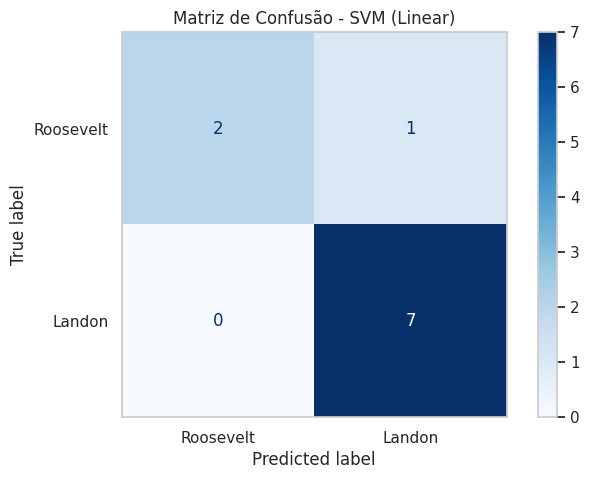

------------------------------------------------------------

==================== SVM (RBF) ====================
Acurácia Média (Validação Cruzada): 0.8179
Acurácia no Teste: 0.9000

              precision    recall  f1-score   support

   Roosevelt       1.00      0.67      0.80         3
      Landon       0.88      1.00      0.93         7

    accuracy                           0.90        10
   macro avg       0.94      0.83      0.87        10
weighted avg       0.91      0.90      0.89        10



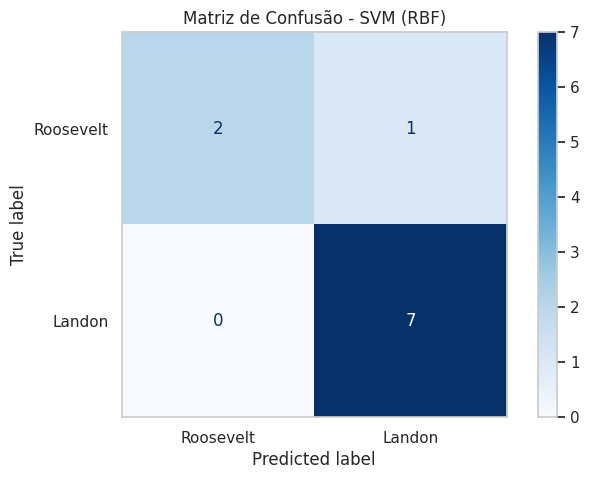

------------------------------------------------------------

==================== SVM (Polinomial) ====================
Acurácia Média (Validação Cruzada): 0.7643
Acurácia no Teste: 0.7000

              precision    recall  f1-score   support

   Roosevelt       0.50      0.33      0.40         3
      Landon       0.75      0.86      0.80         7

    accuracy                           0.70        10
   macro avg       0.62      0.60      0.60        10
weighted avg       0.68      0.70      0.68        10



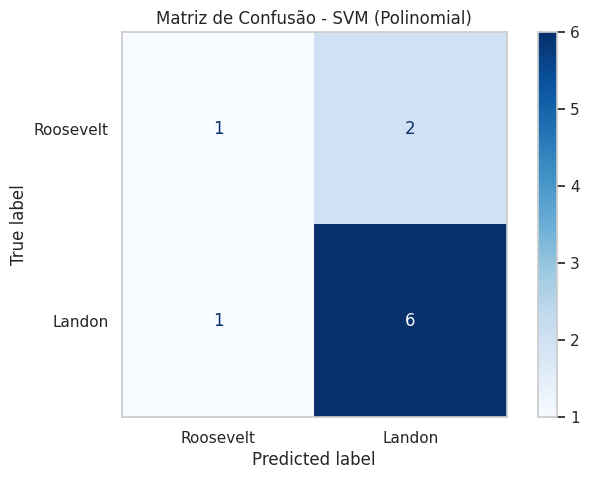

------------------------------------------------------------

==================== SVM (Sigmoide) ====================
Acurácia Média (Validação Cruzada): 0.7893
Acurácia no Teste: 0.8000

              precision    recall  f1-score   support

   Roosevelt       1.00      0.33      0.50         3
      Landon       0.78      1.00      0.88         7

    accuracy                           0.80        10
   macro avg       0.89      0.67      0.69        10
weighted avg       0.84      0.80      0.76        10



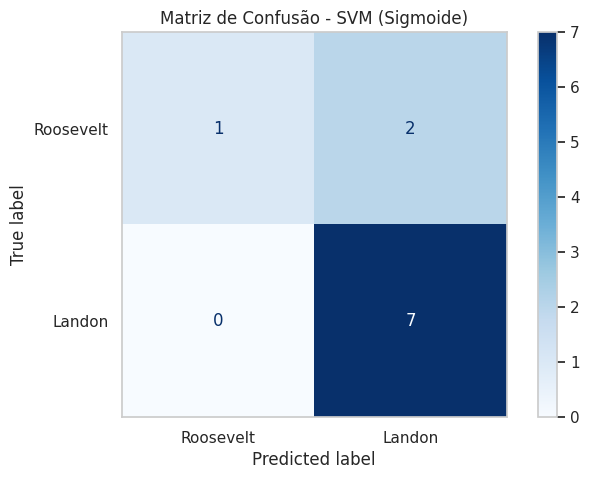

------------------------------------------------------------

==================== Árvore de Decisão ====================
Acurácia Média (Validação Cruzada): 0.6893
Acurácia no Teste: 0.7000

              precision    recall  f1-score   support

   Roosevelt       0.50      0.67      0.57         3
      Landon       0.83      0.71      0.77         7

    accuracy                           0.70        10
   macro avg       0.67      0.69      0.67        10
weighted avg       0.73      0.70      0.71        10



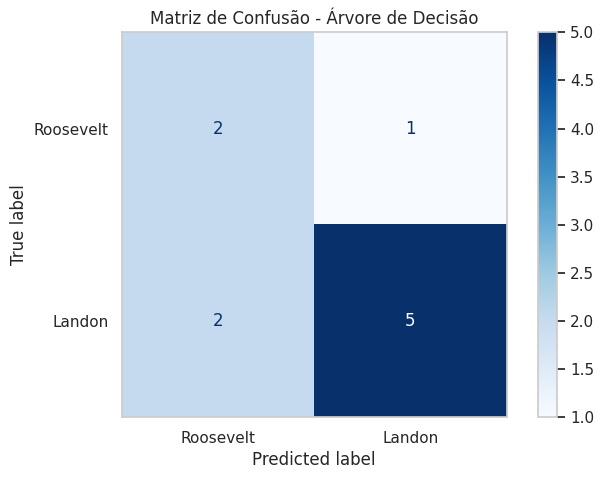

------------------------------------------------------------

==================== Floresta Aleatória ====================
Acurácia Média (Validação Cruzada): 0.7643
Acurácia no Teste: 0.8000

              precision    recall  f1-score   support

   Roosevelt       0.67      0.67      0.67         3
      Landon       0.86      0.86      0.86         7

    accuracy                           0.80        10
   macro avg       0.76      0.76      0.76        10
weighted avg       0.80      0.80      0.80        10



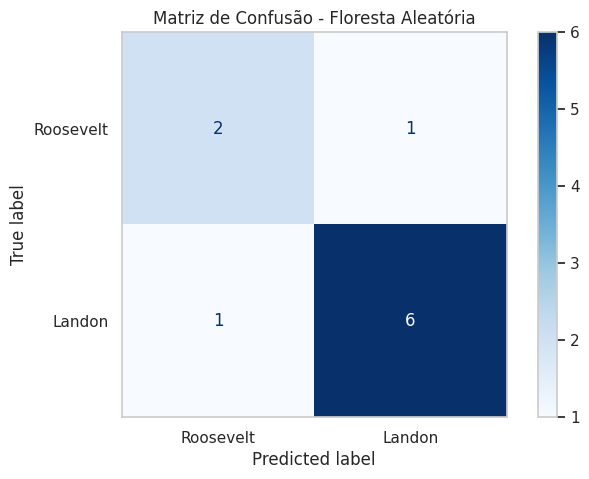

------------------------------------------------------------

==================== Gradient Boosting ====================
Acurácia Média (Validação Cruzada): 0.7357
Acurácia no Teste: 0.8000

              precision    recall  f1-score   support

   Roosevelt       0.67      0.67      0.67         3
      Landon       0.86      0.86      0.86         7

    accuracy                           0.80        10
   macro avg       0.76      0.76      0.76        10
weighted avg       0.80      0.80      0.80        10



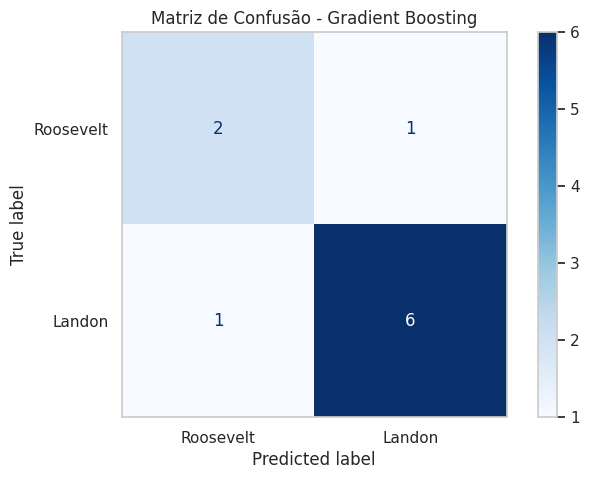

------------------------------------------------------------

=== RESUMO COMPARATIVO DOS MODELOS ===
                    Acurácia Média (CV)  Acurácia (Teste)
SVM (Linear)                   0.846429               0.9
SVM (RBF)                      0.817857               0.9
SVM (Sigmoide)                 0.789286               0.8
Gradient Boosting              0.735714               0.8
Floresta Aleatória             0.764286               0.8
SVM (Polinomial)               0.764286               0.7
Árvore de Decisão              0.689286               0.7

DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: SVM (Linear)
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.


In [ ]:
results = {}

for name, model in models.items():
    # Validação Cruzada (5 folds) na base de treino
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

    # Treino e Predição
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'Acurácia Média (CV)': cv_scores.mean(),
        'Acurácia (Teste)': test_acc
    }

    print(f"\n==================== {name} ====================")
    print(f"Acurácia Média (Validação Cruzada): {cv_scores.mean():.4f}")
    print(f"Acurácia no Teste: {test_acc:.4f}\n")
    print(classification_report(y_test, y_pred, target_names=['Roosevelt', 'Landon'], zero_division=0))

    # Exibição da Matriz de Confusão
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Roosevelt', 'Landon'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Matriz de Confusão - {name}")
    plt.grid(False)
    plt.show()
    print("-" * 60)

# Resumo Final em Tabela
df_resumo = pd.DataFrame(results).T.sort_values(by='Acurácia (Teste)', ascending=False)
print("\n=== RESUMO COMPARATIVO DOS MODELOS ===")
print(df_resumo)

# Identificação segura das colunas (português ou inglês)
col_cv = 'Acurácia Média (CV)' if 'Acurácia Média (CV)' in df_resumo.columns else 'CV Mean Accuracy'
col_test = 'Acurácia (Teste)' if 'Acurácia (Teste)' in df_resumo.columns else 'Test Accuracy'

# Diagnóstico Técnico do Melhor Modelo
melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, col_cv]
acc_test = df_resumo.loc[melhor_modelo, col_test]

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")

if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")

---
# Prova turma A

In [ ]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
dataset_repo = "mfarhaannazirkhan/heart-dataset"

path = kagglehub.dataset_download(dataset_repo)
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
df = pd.read_csv(os.path.join(path, csv_files[0]))

print(f"Dataset '{dataset_repo}' baixado e carregado com sucesso!")

Using Colab cache for faster access to the 'heart-dataset' dataset.
Dataset 'mfarhaannazirkhan/heart-dataset' baixado e carregado com sucesso!


In [ ]:
print("ESTRUTURA DO DATASET (LINHAS, COLUNAS)")
print(df.shape)

print("\nPRIMEIRAS 5 LINHAS")
display(df.head())

print("\nTIPOS DE DADOS E INFORMAÇÕES")
print(df.info())

ESTRUTURA DO DATASET (LINHAS, COLUNAS)
(2181, 14)

PRIMEIRAS 5 LINHAS


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



TIPOS DE DADOS E INFORMAÇÕES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2181 entries, 0 to 2180
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2181 non-null   int64  
 1   sex       2181 non-null   int64  
 2   cp        2181 non-null   int64  
 3   trestbps  2181 non-null   object 
 4   chol      2181 non-null   object 
 5   fbs       2181 non-null   object 
 6   restecg   2181 non-null   object 
 7   thalachh  2181 non-null   object 
 8   exang     2181 non-null   object 
 9   oldpeak   2181 non-null   float64
 10  slope     2181 non-null   object 
 11  ca        2181 non-null   object 
 12  thal      2181 non-null   object 
 13  target    2181 non-null   int64  
dtypes: float64(1), int64(4), object(9)
memory usage: 238.7+ KB
None


In [ ]:
# Remoção de duplicatas
duplicadas = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Linhas duplicadas removidas: {duplicadas}")

# Identificação da variável alvo (target ou última coluna)
alvo = [c for c in df.columns if any(k in c.lower() for k in ['target', 'heart', 'disease', 'class', 'label'])]
alvo = alvo[0] if alvo else df.columns[-1]

print(f"Variável Alvo Identificada: '{alvo}'")
print("\nVALORES FALTANTES (NaN) POR COLUNA")
print(df.isnull().sum())

Linhas duplicadas removidas: 1287
Variável Alvo Identificada: 'target'

VALORES FALTANTES (NaN) POR COLUNA
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalachh    0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,894.0,52.302013,9.205776,28.0,45.0,53.0,59.0,77.0
sex,894.0,0.697987,0.459388,0.0,0.0,1.0,1.0,1.0
cp,894.0,1.665548,1.126391,0.0,1.0,2.0,3.0,3.0
oldpeak,894.0,0.913758,1.105398,0.0,0.0,0.5,1.5,6.2
target,894.0,0.444072,0.497140,0.0,0.0,0.0,1.0,1.0


/tmp/ipykernel_1838/618716499.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=alvo, palette="Set2")


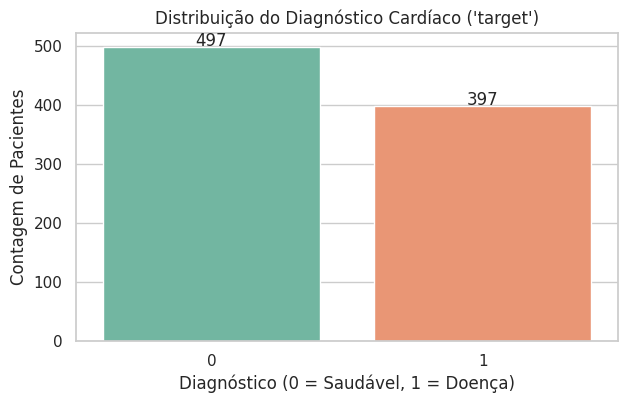

In [ ]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x=alvo, palette="Set2")
plt.title(f"Distribuição do Diagnóstico Cardíaco ('{alvo}')")
plt.xlabel("Diagnóstico (0 = Saudável, 1 = Doença)")
plt.ylabel("Contagem de Pacientes")

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

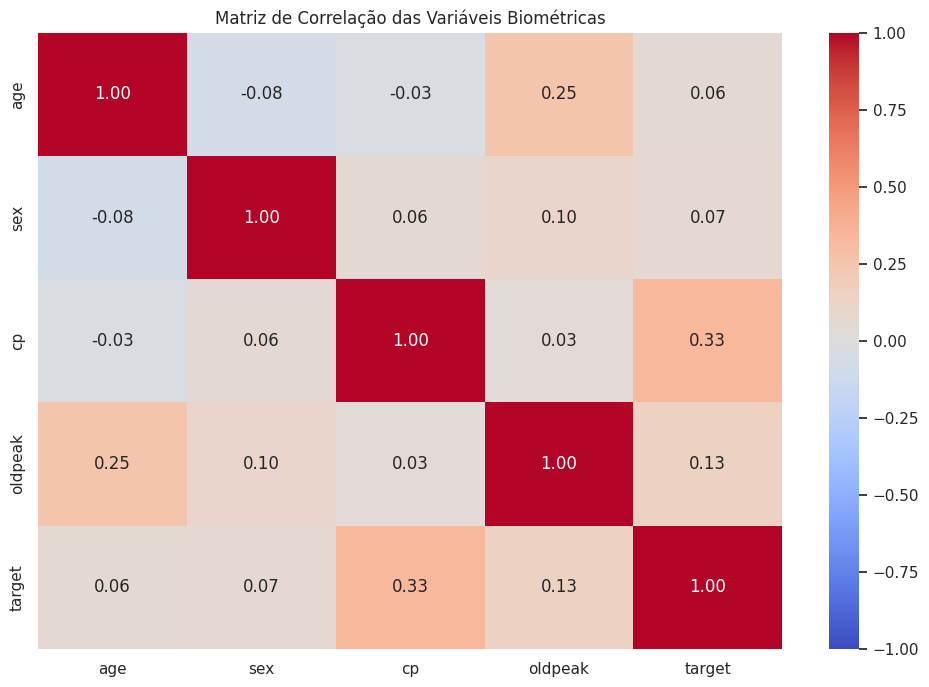

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação das Variáveis Biométricas")
plt.show()

In [ ]:
# Filtra classes com menos de 2 elementos para garantir a estratificação
contagem_classes = df[alvo].value_counts()
classes_validas = contagem_classes[contagem_classes >= 2].index
df_filtrado = df[df[alvo].isin(classes_validas)].copy()

X = df_filtrado.drop(columns=[alvo])
y = df_filtrado[alvo]

# One-Hot Encoding e tratamento de nulos
X = pd.get_dummies(X, drop_first=True)
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Amostras de Treino: {len(X_train)} | Amostras de Teste: {len(X_test)}")

Amostras de Treino: 715 | Amostras de Teste: 179



SVM (Linear)
CV Acc (5-fold): 0.6434 | Test Acc: 0.6369 | F1: 0.6346 | ROC-AUC: 0.6545


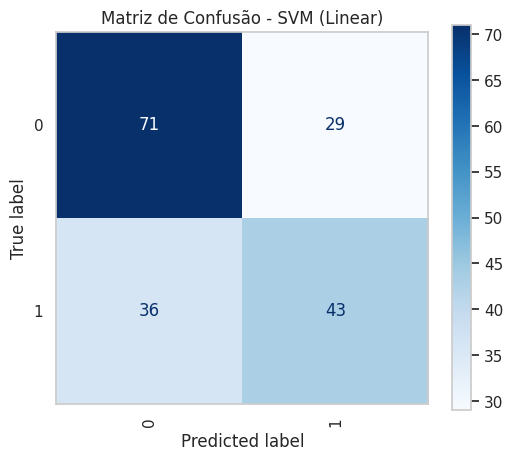

------------------------------------------------------------

SVM (RBF)
CV Acc (5-fold): 0.5902 | Test Acc: 0.5754 | F1: 0.5657 | ROC-AUC: 0.5957


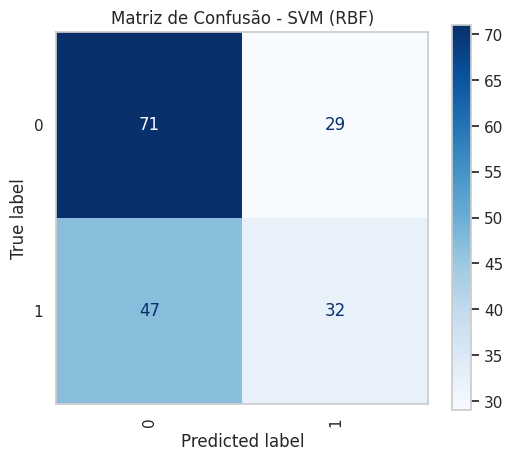

------------------------------------------------------------

SVM (Polinomial)
CV Acc (5-fold): 0.4643 | Test Acc: 0.4916 | F1: 0.3912 | ROC-AUC: 0.7156


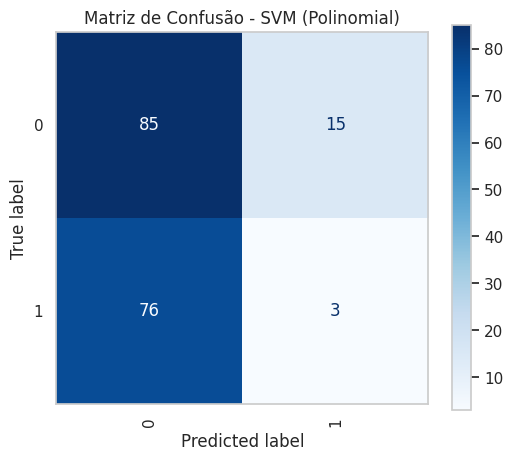

------------------------------------------------------------

SVM (Sigmoide)
CV Acc (5-fold): 0.7413 | Test Acc: 0.6927 | F1: 0.6915 | ROC-AUC: 0.7735


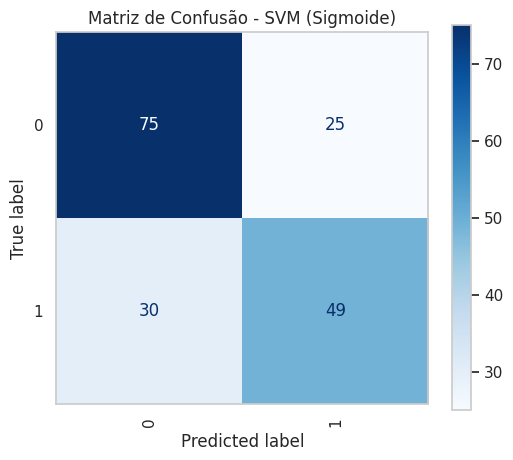

------------------------------------------------------------

Árvore de Decisão
CV Acc (5-fold): 0.7650 | Test Acc: 0.7598 | F1: 0.7604 | ROC-AUC: 0.7597


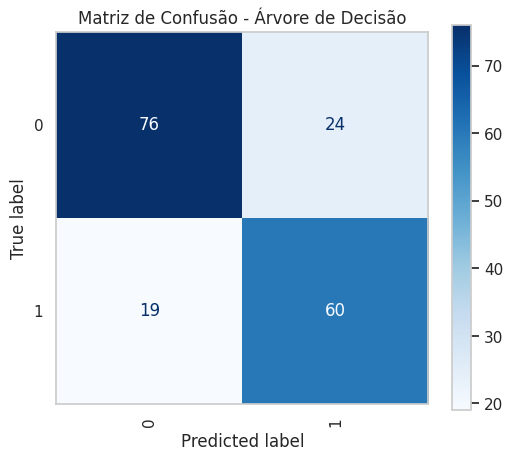

------------------------------------------------------------

Floresta Aleatória
CV Acc (5-fold): 0.8308 | Test Acc: 0.7821 | F1: 0.7808 | ROC-AUC: 0.8628


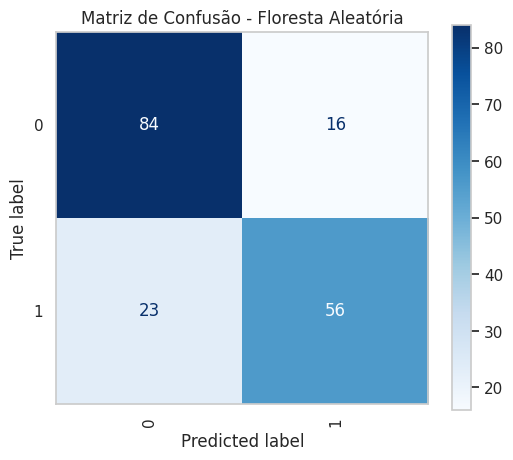

------------------------------------------------------------

Gradient Boosting
CV Acc (5-fold): 0.8056 | Test Acc: 0.7598 | F1: 0.7583 | ROC-AUC: 0.8550


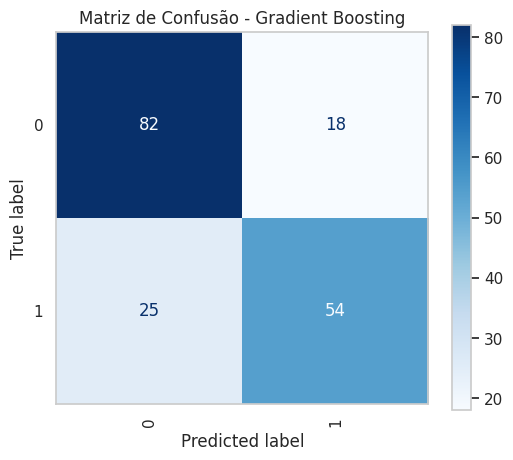

------------------------------------------------------------


In [ ]:
models = {
    "SVM (Linear)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='linear', probability=True, random_state=42))]),
    "SVM (RBF)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', probability=True, random_state=42))]),
    "SVM (Polinomial)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='poly', degree=3, probability=True, random_state=42))]),
    "SVM (Sigmoide)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='sigmoid', probability=True, random_state=42))]),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Floresta Aleatória": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = {}
n_classes = len(np.unique(y))
cv_folds = min(5, int(y_train.value_counts().min()))

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv_folds, scoring='accuracy')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    if n_classes == 2:
        roc_auc = roc_auc_score(y_test, y_proba[:, 1])
    else:
        roc_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')

    results[name] = {
        'Acurácia (CV)': cv_scores.mean(),
        'Acurácia (Teste)': acc,
        'Precisão': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    print(f"\n{name}")
    print(f"CV Acc ({cv_folds}-fold): {cv_scores.mean():.4f} | Test Acc: {acc:.4f} | F1: {f1:.4f} | ROC-AUC: {roc_auc:.4f}")

    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation='vertical')
    plt.title(f"Matriz de Confusão - {name}")
    plt.grid(False)
    plt.show()
    print("-" * 60)

In [ ]:
df_resumo = pd.DataFrame(results).T.sort_values(by='F1-Score', ascending=False)
print("RESUMO COMPARATIVO COMPLETO DAS MÉTRICAS")
display(df_resumo)

# Identificação dinâmica das colunas (funciona em português ou inglês)
col_cv = 'Acurácia (CV)' if 'Acurácia (CV)' in df_resumo.columns else ('Acurácia Média (CV)' if 'Acurácia Média (CV)' in df_resumo.columns else 'CV Mean Accuracy')
col_test = 'Acurácia (Teste)' if 'Acurácia (Teste)' in df_resumo.columns else 'Test Accuracy'

melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, col_cv]
acc_test = df_resumo.loc[melhor_modelo, col_test]

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")

if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")

RESUMO COMPARATIVO COMPLETO DAS MÉTRICAS


,Acurácia (CV),Acurácia (Teste),Precisão,Recall,F1-Score,ROC-AUC
Floresta Aleatória,0.830769,0.782123,0.781839,0.782123,0.780757,0.862785
Árvore de Decisão,0.765035,0.759777,0.762171,0.759777,0.760381,0.759747
Gradient Boosting,0.805594,0.759777,0.759137,0.759777,0.758270,0.855000
SVM (Sigmoide),0.741259,0.692737,0.691281,0.692737,0.691464,0.773544
SVM (Linear),0.643357,0.636872,0.634278,0.636872,0.634594,0.654494
SVM (RBF),0.590210,0.575419,0.567665,0.575419,0.565653,0.595696
SVM (Polinomial),0.464336,0.491620,0.368501,0.491620,0.391177,0.715570



DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: Floresta Aleatória
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.


---
# Prova turma B

In [ ]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
dataset_repo = "rxnach/student-stress-factors-a-comprehensive-analysis"

path = kagglehub.dataset_download(dataset_repo)
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
df = pd.read_csv(os.path.join(path, csv_files[0]))

print(f"Dataset '{dataset_repo}' baixado e carregado com sucesso!")

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
Dataset 'rxnach/student-stress-factors-a-comprehensive-analysis' baixado e carregado com sucesso!


In [ ]:
print("ESTRUTURA DO DATASET (LINHAS, COLUNAS)")
print(df.shape)

print("\nPRIMEIRAS 5 LINHAS")
display(df.head())

print("\nIPOS DE DADOS E INFORMAÇÕES")
print(df.info())

ESTRUTURA DO DATASET (LINHAS, COLUNAS)
(1100, 21)

PRIMEIRAS 5 LINHAS


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1



IPOS DE DADOS E INFORMAÇÕES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  stud

In [ ]:
# Remoção de duplicatas
duplicadas = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Linhas duplicadas removidas: {duplicadas}")

# Identificação da variável alvo (estresse)
alvo = [c for c in df.columns if any(k in c.lower() for k in ['stress', 'target', 'class', 'label'])]
alvo = alvo[0] if alvo else df.columns[-1]

print(f"Variável Alvo Identificada: '{alvo}'")
print("\nVALORES FALTANTES (NaN) POR COLUNA")
print(df.isnull().sum())

Linhas duplicadas removidas: 0
Variável Alvo Identificada: 'stress_level'

VALORES FALTANTES (NaN) POR COLUNA
anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64


In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
anxiety_level,1100.0,11.063636,6.117558,0.0,6.0,11.0,16.0,21.0
self_esteem,1100.0,17.777273,8.944599,0.0,11.0,19.0,26.0,30.0
mental_health_history,1100.0,0.492727,0.500175,0.0,0.0,0.0,1.0,1.0
depression,1100.0,12.555455,7.727008,0.0,6.0,12.0,19.0,27.0
headache,1100.0,2.508182,1.409356,0.0,1.0,3.0,3.0,5.0
blood_pressure,1100.0,2.181818,0.833575,1.0,1.0,2.0,3.0,3.0
sleep_quality,1100.0,2.660000,1.548383,0.0,1.0,2.5,4.0,5.0
breathing_problem,1100.0,2.753636,1.400713,0.0,2.0,3.0,4.0,5.0
noise_level,1100.0,2.649091,1.328127,0.0,2.0,3.0,3.0,5.0
living_conditions,1100.0,2.518182,1.119208,0.0,2.0,2.0,3.0,5.0


/tmp/ipykernel_1838/3548731095.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=alvo, palette="Set2")


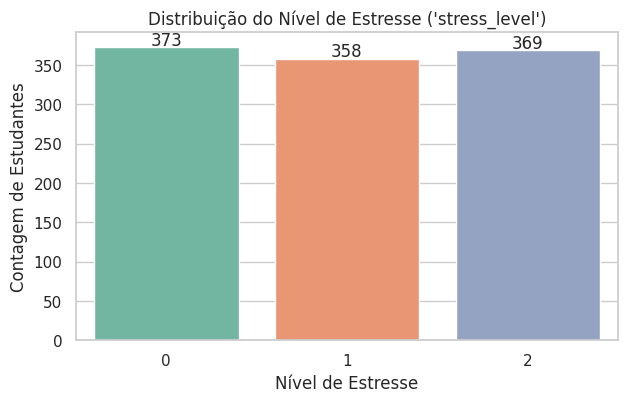

In [ ]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x=alvo, palette="Set2")
plt.title(f"Distribuição do Nível de Estresse ('{alvo}')")
plt.xlabel("Nível de Estresse")
plt.ylabel("Contagem de Estudantes")

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

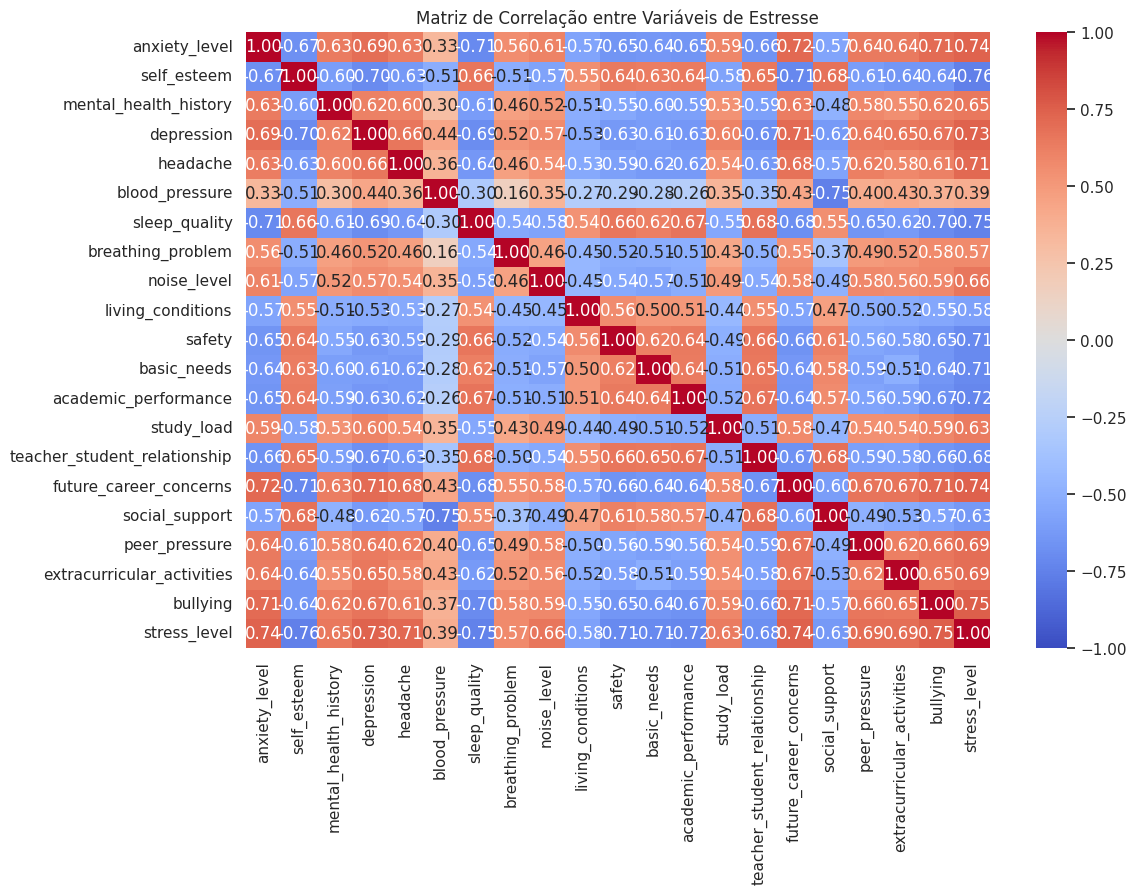

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação entre Variáveis de Estresse")
plt.show()

In [ ]:
# Filtra classes com menos de 2 elementos para garantir a estratificação
contagem_classes = df[alvo].value_counts()
classes_validas = contagem_classes[contagem_classes >= 2].index
df_filtrado = df[df[alvo].isin(classes_validas)].copy()

X = df_filtrado.drop(columns=[alvo])
y = df_filtrado[alvo]

# Dummies e tratamento de nulos
X = pd.get_dummies(X, drop_first=True)
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Amostras de Treino: {len(X_train)} | Amostras de Teste: {len(X_test)}")

Amostras de Treino: 880 | Amostras de Teste: 220



SVM (Linear)
CV Acc (5-fold): 0.8841 | Test Acc: 0.8864 | F1: 0.8858 | ROC-AUC: 0.9556


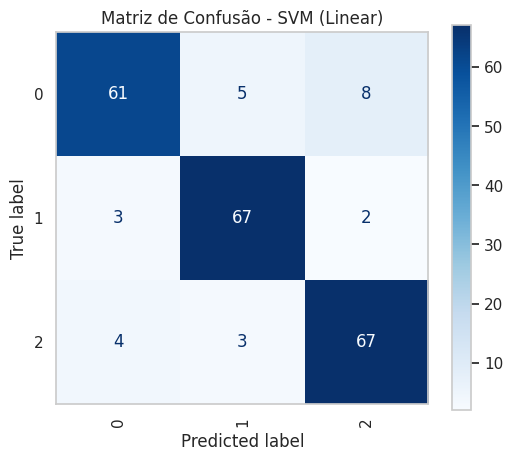

------------------------------------------------------------

SVM (RBF)
CV Acc (5-fold): 0.8739 | Test Acc: 0.8773 | F1: 0.8771 | ROC-AUC: 0.9845


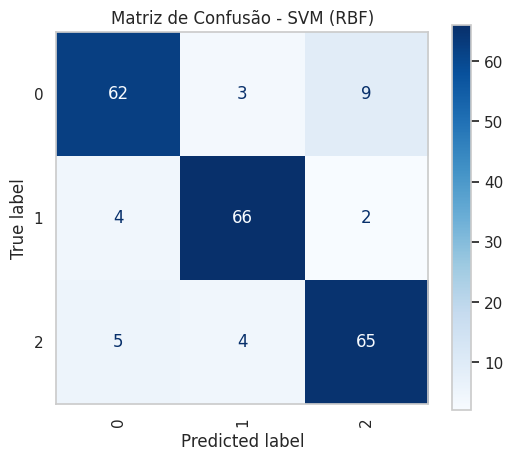

------------------------------------------------------------

SVM (Polinomial)
CV Acc (5-fold): 0.8625 | Test Acc: 0.8682 | F1: 0.8682 | ROC-AUC: 0.9774


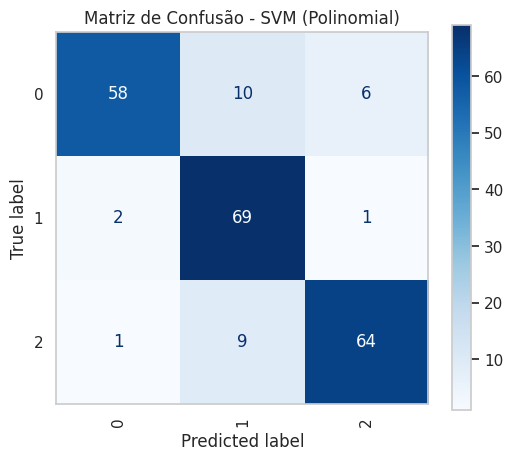

------------------------------------------------------------

SVM (Sigmoide)
CV Acc (5-fold): 0.8795 | Test Acc: 0.8955 | F1: 0.8961 | ROC-AUC: 0.9398


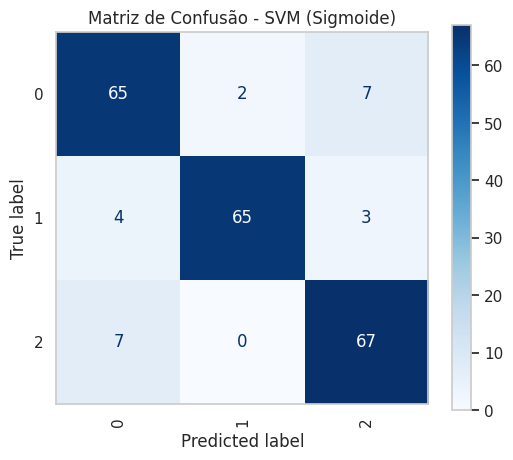

------------------------------------------------------------

Árvore de Decisão
CV Acc (5-fold): 0.8784 | Test Acc: 0.8545 | F1: 0.8542 | ROC-AUC: 0.8911


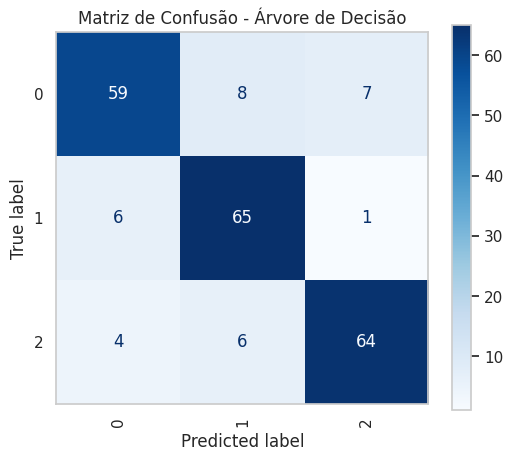

------------------------------------------------------------

Floresta Aleatória
CV Acc (5-fold): 0.8807 | Test Acc: 0.8909 | F1: 0.8907 | ROC-AUC: 0.9829


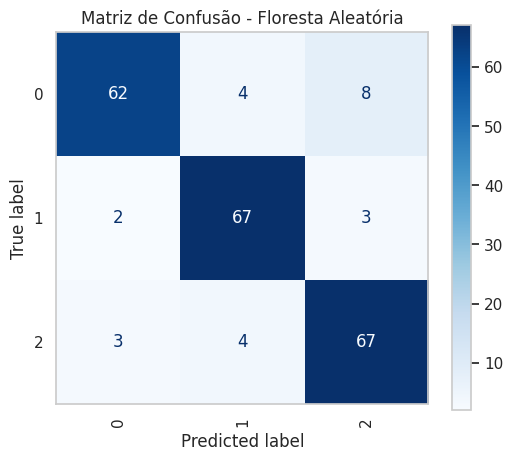

------------------------------------------------------------

Gradient Boosting
CV Acc (5-fold): 0.8875 | Test Acc: 0.8727 | F1: 0.8722 | ROC-AUC: 0.9825


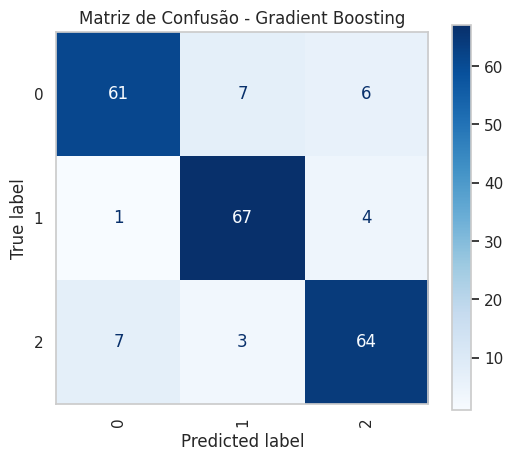

------------------------------------------------------------


In [ ]:
models = {
    "SVM (Linear)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='linear', probability=True, random_state=42))]),
    "SVM (RBF)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', probability=True, random_state=42))]),
    "SVM (Polinomial)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='poly', degree=3, probability=True, random_state=42))]),
    "SVM (Sigmoide)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='sigmoid', probability=True, random_state=42))]),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Floresta Aleatória": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = {}
n_classes = len(np.unique(y))
cv_folds = min(5, int(y_train.value_counts().min()))

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv_folds, scoring='accuracy')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    if n_classes == 2:
        roc_auc = roc_auc_score(y_test, y_proba[:, 1])
    else:
        roc_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')

    results[name] = {
        'Acurácia (CV)': cv_scores.mean(),
        'Acurácia (Teste)': acc,
        'Precisão': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    print(f"\n{name}")
    print(f"CV Acc ({cv_folds}-fold): {cv_scores.mean():.4f} | Test Acc: {acc:.4f} | F1: {f1:.4f} | ROC-AUC: {roc_auc:.4f}")

    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation='vertical')
    plt.title(f"Matriz de Confusão - {name}")
    plt.grid(False)
    plt.show()
    print("-" * 60)

In [ ]:
df_resumo = pd.DataFrame(results).T.sort_values(by='F1-Score', ascending=False)
print("RESUMO COMPARATIVO COMPLETO DAS MÉTRICAS")
display(df_resumo)

melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, 'Acurácia (CV)']
acc_test = df_resumo.loc[melhor_modelo, 'Acurácia (Teste)']

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")
if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")

RESUMO COMPARATIVO COMPLETO DAS MÉTRICAS


,Acurácia (CV),Acurácia (Teste),Precisão,Recall,F1-Score,ROC-AUC
SVM (Sigmoide),0.879545,0.895455,0.897863,0.895455,0.896092,0.939784
Floresta Aleatória,0.880682,0.890909,0.892553,0.890909,0.890670,0.982920
SVM (Linear),0.884091,0.886364,0.886782,0.886364,0.885814,0.955551
SVM (RBF),0.873864,0.877273,0.877296,0.877273,0.877095,0.984514
Gradient Boosting,0.887500,0.872727,0.873044,0.872727,0.872202,0.982506
SVM (Polinomial),0.862500,0.868182,0.879634,0.868182,0.868224,0.977424
Árvore de Decisão,0.878409,0.854545,0.855880,0.854545,0.854211,0.891059



DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: SVM (Sigmoide)
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.


---
# FISHMORPH Dataset

In [ ]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
csv_file = csv_files[0]

df_fish = pd.read_csv(os.path.join(path, csv_file))
print(f"Dataset baixado e carregado! Arquivo: {csv_file}")

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.
Dataset baixado e carregado! Arquivo: FISHMORPH_Order_Dataset.csv


In [ ]:
print("FORMAÇÃO DO DATASET (LINHAS, COLUNAS)")
print(df_fish.shape)

print("\nPRIMEIRAS 5 LINHAS")
display(df_fish.head())

print("\nTIPOS DE DADOS")
print(df_fish.info())

FORMAÇÃO DO DATASET (LINHAS, COLUNAS)
(8342, 11)

PRIMEIRAS 5 LINHAS


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cypriniformes
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Perciformes
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cypriniformes
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cypriniformes
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cypriniformes



TIPOS DE DADOS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Order   8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB
None


In [ ]:
# Remoção de linhas duplicadas
duplicadas = df_fish.duplicated().sum()
df_fish = df_fish.drop_duplicates()

print(f"Linhas duplicadas removidas: {duplicadas}")
print("\n=== VALORES FALTANTES (NaN) POR COLUNA ===")
print(df_fish.isnull().sum())

# Identificação dinâmica da variável alvo (espécie/família ou última coluna)
alvo = [c for c in df_fish.columns if c.lower() in ['species', 'target', 'class', 'label']]
alvo = alvo[0] if alvo else df_fish.columns[-1]
print(f"\nVariável alvo definida: '{alvo}'")

Linhas duplicadas removidas: 1

=== VALORES FALTANTES (NaN) POR COLUNA ===
MBl      0
BEl      0
VEp      0
REs      0
OGp      0
RMl      0
BLs      0
PFv      0
PFs      0
CPt      0
Order    0
dtype: int64

Variável alvo definida: 'Order'


In [ ]:
display(df_fish.describe().T)

,count,mean,std,min,25%,50%,75%,max
MBl,8341.0,22.001760,33.613078,1.200000,7.000000,12.600000,24.500000,800.000000
BEl,8341.0,4.451783,2.337610,1.033084,3.138589,4.038750,5.002083,43.728161
VEp,8341.0,0.549086,0.094888,0.159248,0.487991,0.546209,0.605130,1.000000
REs,8341.0,0.391689,0.132804,0.000000,0.293273,0.389474,0.486223,1.026667
OGp,8341.0,0.381784,0.194358,0.000000,0.278062,0.406919,0.516016,1.026316
RMl,8341.0,0.399799,0.302674,0.000000,0.257987,0.361448,0.490709,7.060344
BLs,8341.0,0.571821,0.117493,0.224525,0.490050,0.564774,0.648041,1.230105
PFv,8341.0,0.285312,0.155638,0.000000,0.193129,0.275030,0.368883,0.857097
PFs,8341.0,0.189365,0.056074,0.000000,0.157986,0.183505,0.215036,0.511113
CPt,8341.0,2.561102,1.016333,0.000000,1.999776,2.436964,2.919872,15.452061


/tmp/ipykernel_1838/432633797.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_fish, x=alvo, palette="Set2")


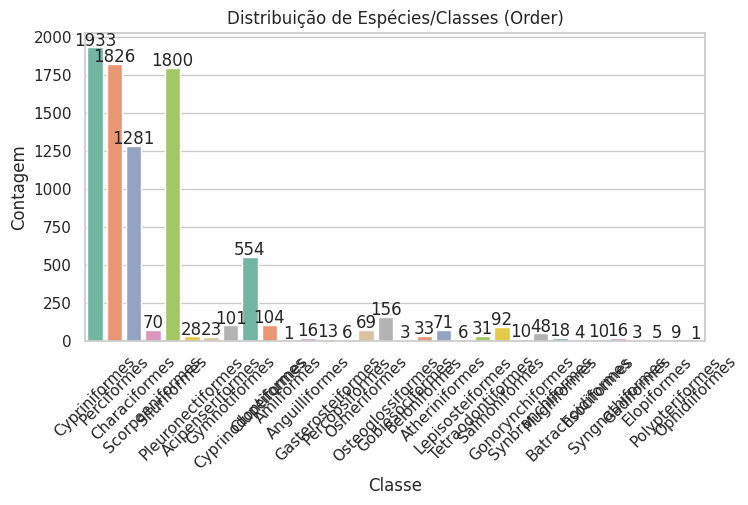

In [ ]:
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df_fish, x=alvo, palette="Set2")
plt.title(f"Distribuição de Espécies/Classes ({alvo})")
plt.xlabel("Classe")
plt.ylabel("Contagem")
plt.xticks(rotation=45)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

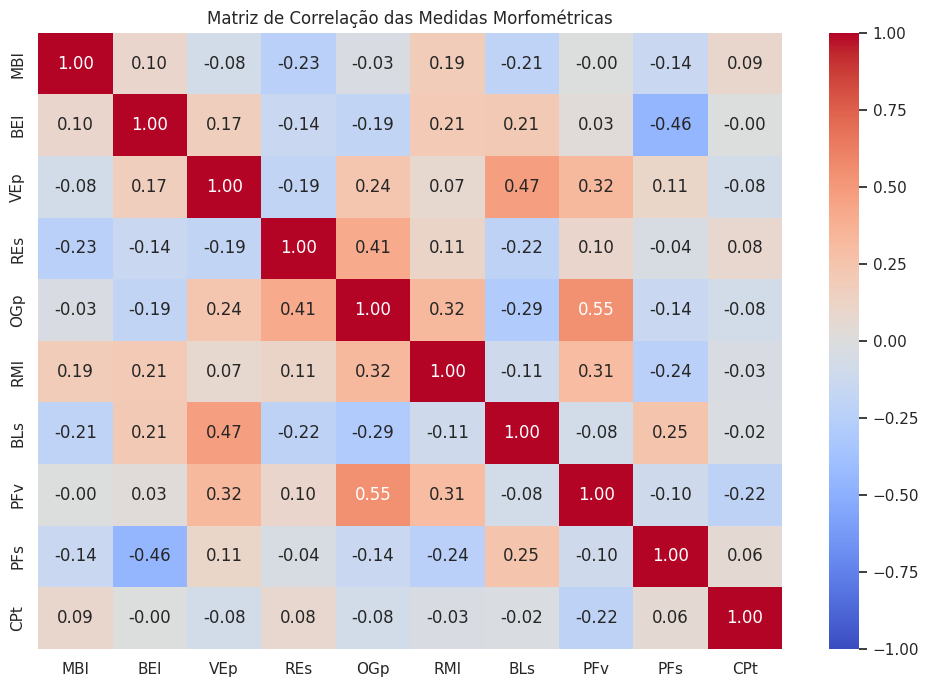

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_fish.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação das Medidas Morfométricas")
plt.show()

In [ ]:
# 1. Identifica a contagem de amostras por classe
contagem_classes = df_fish[alvo].value_counts()

# 2. Filtra mantendo apenas classes com pelo menos 2 registros (necessário para o stratify)
classes_validas = contagem_classes[contagem_classes >= 2].index
df_filtrado = df_fish[df_fish[alvo].isin(classes_validas)].copy()

classes_removidas = len(contagem_classes) - len(classes_validas)
if classes_removidas > 0:
    print(f"Aviso: {classes_removidas} classe(s) com menos de 2 amostras foram removidas para permitir o uso de stratify=y.")

# 3. Separa os recursos (X) e a variável alvo (y)
X = df_filtrado.drop(columns=[alvo])
y = df_filtrado[alvo]

# 4. Trata colunas categóricas e preenche eventuais nulos
X = pd.get_dummies(X, drop_first=True)
X = X.fillna(X.median())

# 5. Divisão em Treino (80%) e Teste (20%) com estratificação mantida
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Amostras de Treino: {len(X_train)} | Amostras de Teste: {len(X_test)}")

Aviso: 2 classe(s) com menos de 2 amostras foram removidas para permitir o uso de stratify=y.
Amostras de Treino: 6671 | Amostras de Teste: 1668



SVM (Linear)
Validação Cruzada (3-fold): 0.6999
Acurácia no Teste: 0.7182

                    precision    recall  f1-score   support

  Acipenseriformes       1.00      0.80      0.89         5
    Anguilliformes       1.00      1.00      1.00         3
    Atheriniformes       0.67      0.43      0.52        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       0.88      1.00      0.93         7
     Characiformes       0.67      0.72      0.69       256
      Clupeiformes       1.00      0.05      0.09        21
     Cypriniformes       0.58      0.64      0.61       387
Cyprinodontiformes       0.81      0.84      0.82       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       0.00      0.00      0.00         2
 Gasterosteiformes       0.00      0.00      0.00         3
  Gonorynchiformes       0.00      0.00      0.00         2
     Gymnotiformes       0.75      0.90      0.82        20
  Lepisosteiformes     

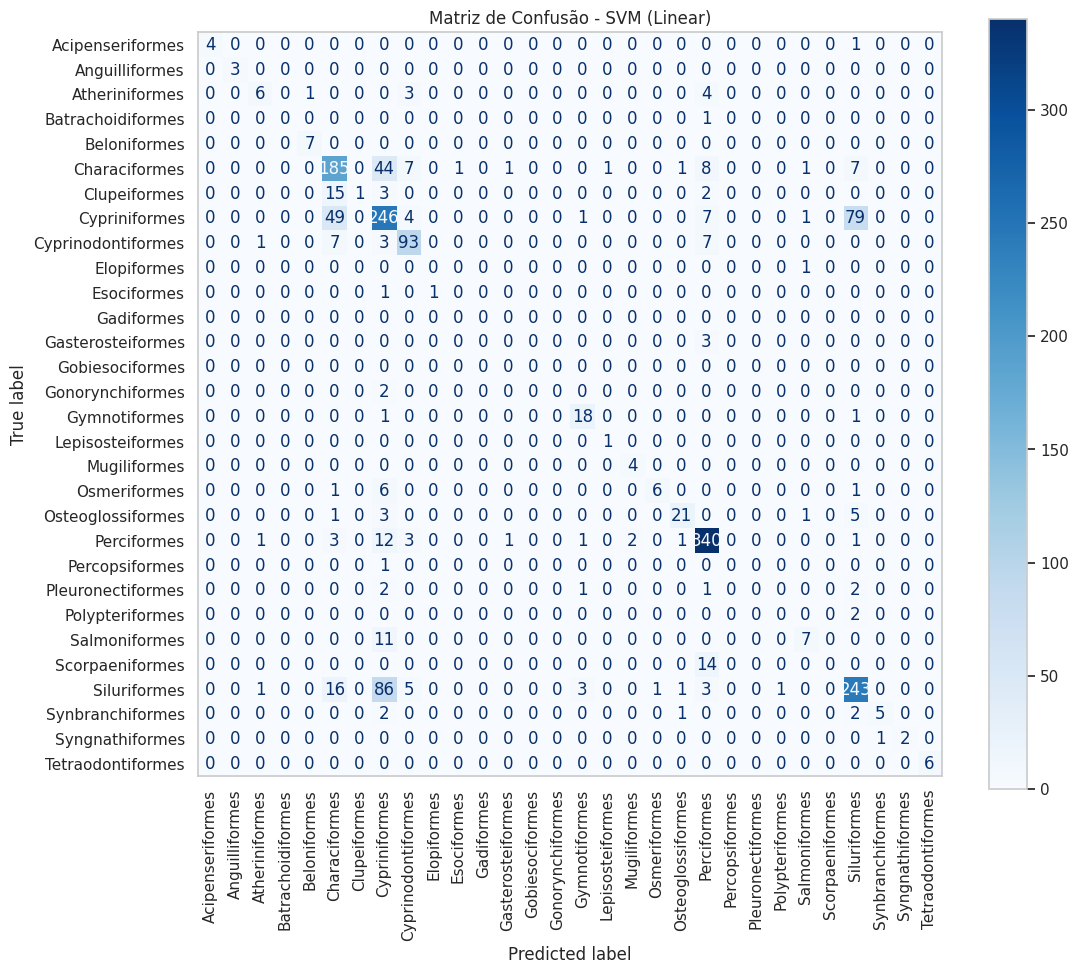

------------------------------------------------------------

SVM (RBF)
Validação Cruzada (3-fold): 0.7594
Acurácia no Teste: 0.7956

                    precision    recall  f1-score   support

  Acipenseriformes       1.00      0.60      0.75         5
    Anguilliformes       1.00      0.33      0.50         3
    Atheriniformes       0.67      0.71      0.69        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       1.00      0.86      0.92         7
     Characiformes       0.80      0.75      0.78       256
      Clupeiformes       0.60      0.14      0.23        21
     Cypriniformes       0.68      0.80      0.74       387
Cyprinodontiformes       0.86      0.87      0.87       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       0.00      0.00      0.00         2
 Gasterosteiformes       0.00      0.00      0.00         3
  Gonorynchiformes       0.00      0.00      0.00         2
     Gymnotiformes       

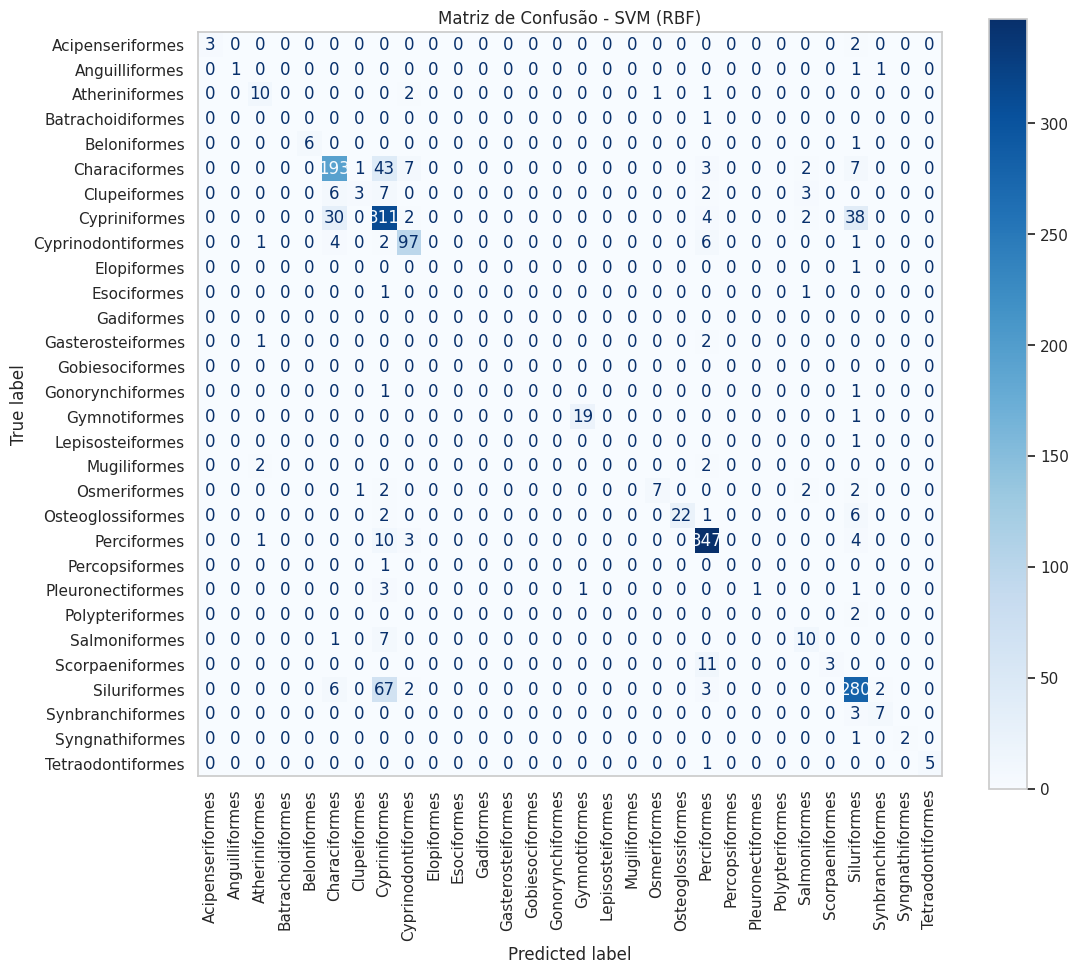

------------------------------------------------------------

SVM (Polinomial)
Validação Cruzada (3-fold): 0.6677
Acurácia no Teste: 0.7140

                    precision    recall  f1-score   support

  Acipenseriformes       0.40      0.40      0.40         5
    Anguilliformes       1.00      1.00      1.00         3
    Atheriniformes       1.00      0.57      0.73        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       0.78      1.00      0.88         7
     Characiformes       0.80      0.57      0.67       256
      Clupeiformes       0.40      0.10      0.15        21
     Cypriniformes       0.51      0.87      0.64       387
Cyprinodontiformes       0.84      0.69      0.76       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       0.00      0.00      0.00         2
 Gasterosteiformes       0.00      0.00      0.00         3
  Gonorynchiformes       0.00      0.00      0.00         2
     Gymnotiformes

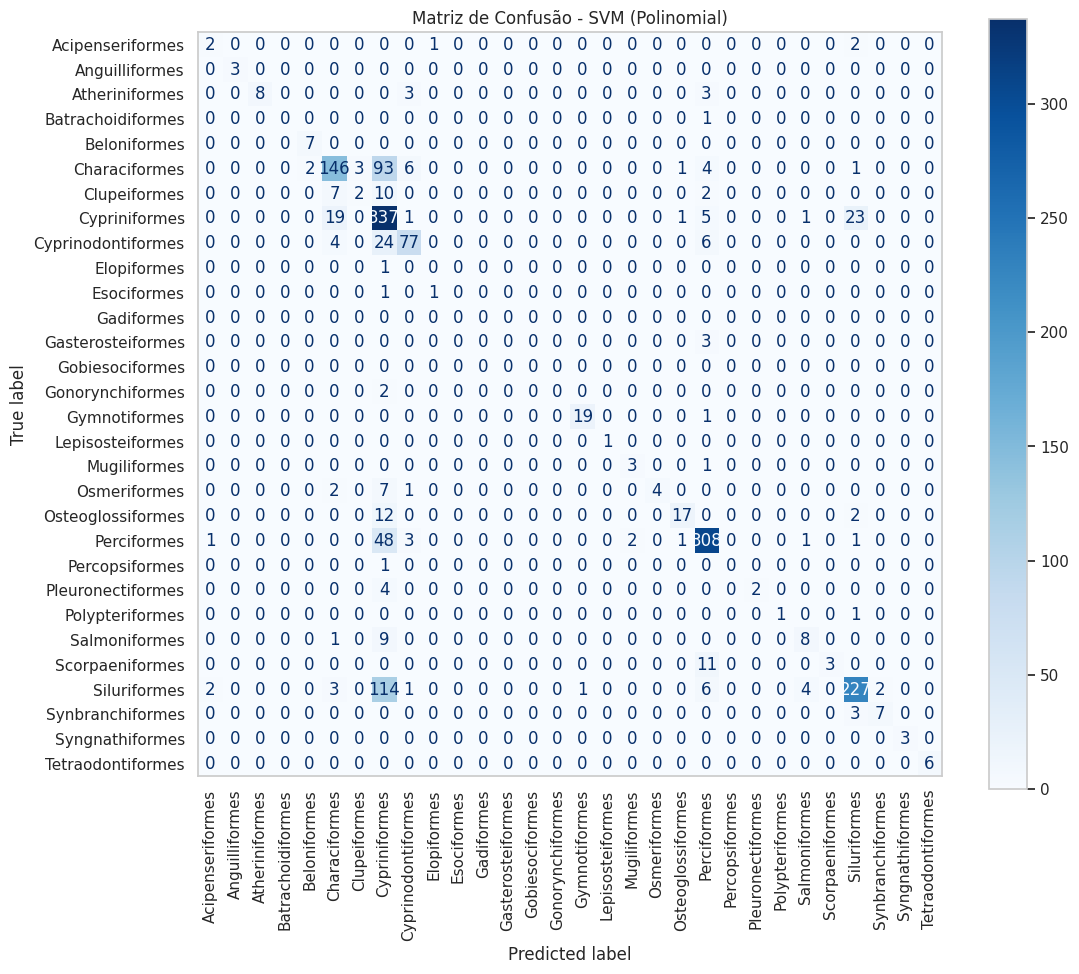

------------------------------------------------------------

SVM (Sigmoide)
Validação Cruzada (3-fold): 0.5209
Acurácia no Teste: 0.5330

                    precision    recall  f1-score   support

  Acipenseriformes       0.00      0.00      0.00         5
    Anguilliformes       0.00      0.00      0.00         3
    Atheriniformes       0.71      0.36      0.48        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       0.00      0.00      0.00         7
     Characiformes       0.57      0.61      0.59       256
      Clupeiformes       0.40      0.10      0.15        21
     Cypriniformes       0.39      0.41      0.40       387
Cyprinodontiformes       0.71      0.62      0.66       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       0.00      0.00      0.00         2
 Gasterosteiformes       0.00      0.00      0.00         3
  Gonorynchiformes       0.00      0.00      0.00         2
     Gymnotiformes  

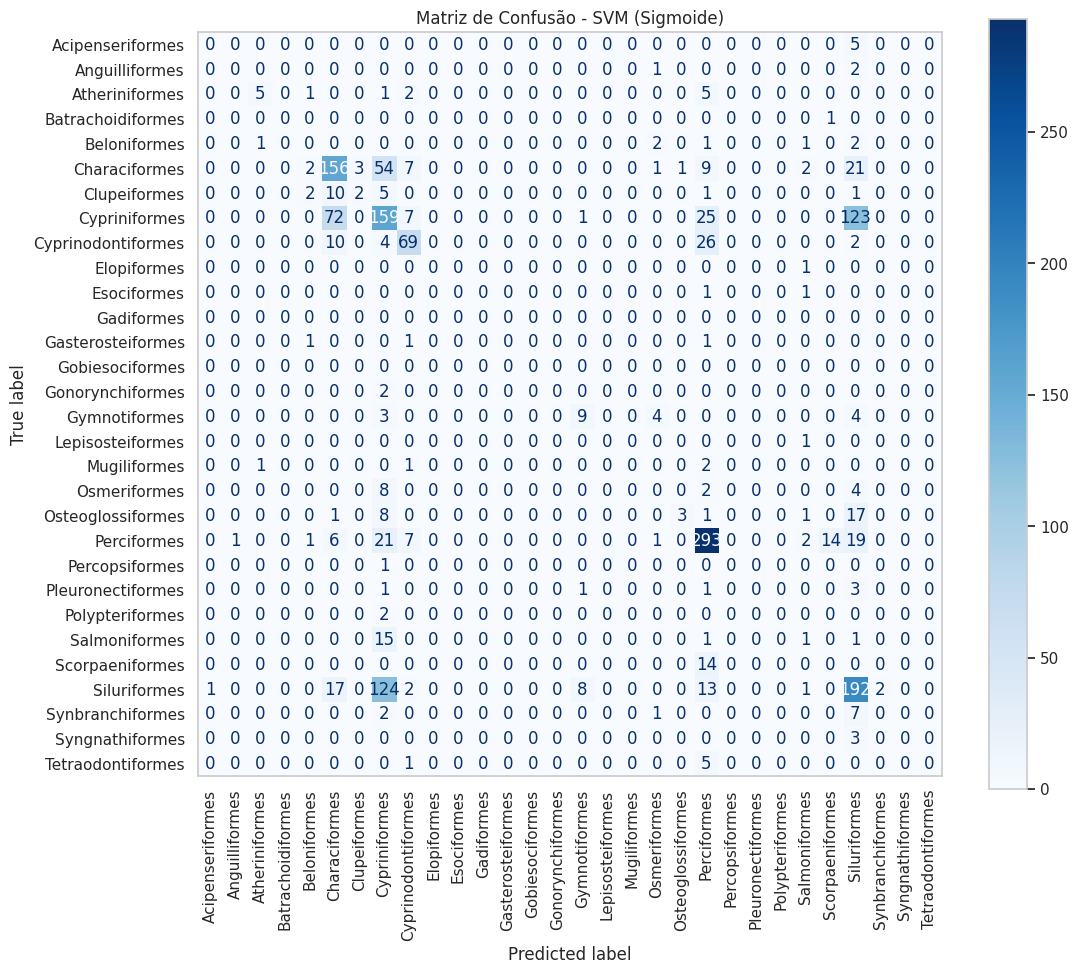

------------------------------------------------------------

Árvore de Decisão
Validação Cruzada (3-fold): 0.6254
Acurácia no Teste: 0.6277

                    precision    recall  f1-score   support

  Acipenseriformes       0.75      0.60      0.67         5
    Anguilliformes       0.67      0.67      0.67         3
    Atheriniformes       0.44      0.29      0.35        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       0.43      0.86      0.57         7
     Characiformes       0.62      0.64      0.63       256
      Clupeiformes       0.19      0.24      0.21        21
     Cypriniformes       0.55      0.54      0.54       387
Cyprinodontiformes       0.63      0.60      0.61       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       0.25      0.50      0.33         2
        Gadiformes       0.00      0.00      0.00         0
 Gasterosteiformes       0.00      0.00      0.00         3
  Gonorynchiforme

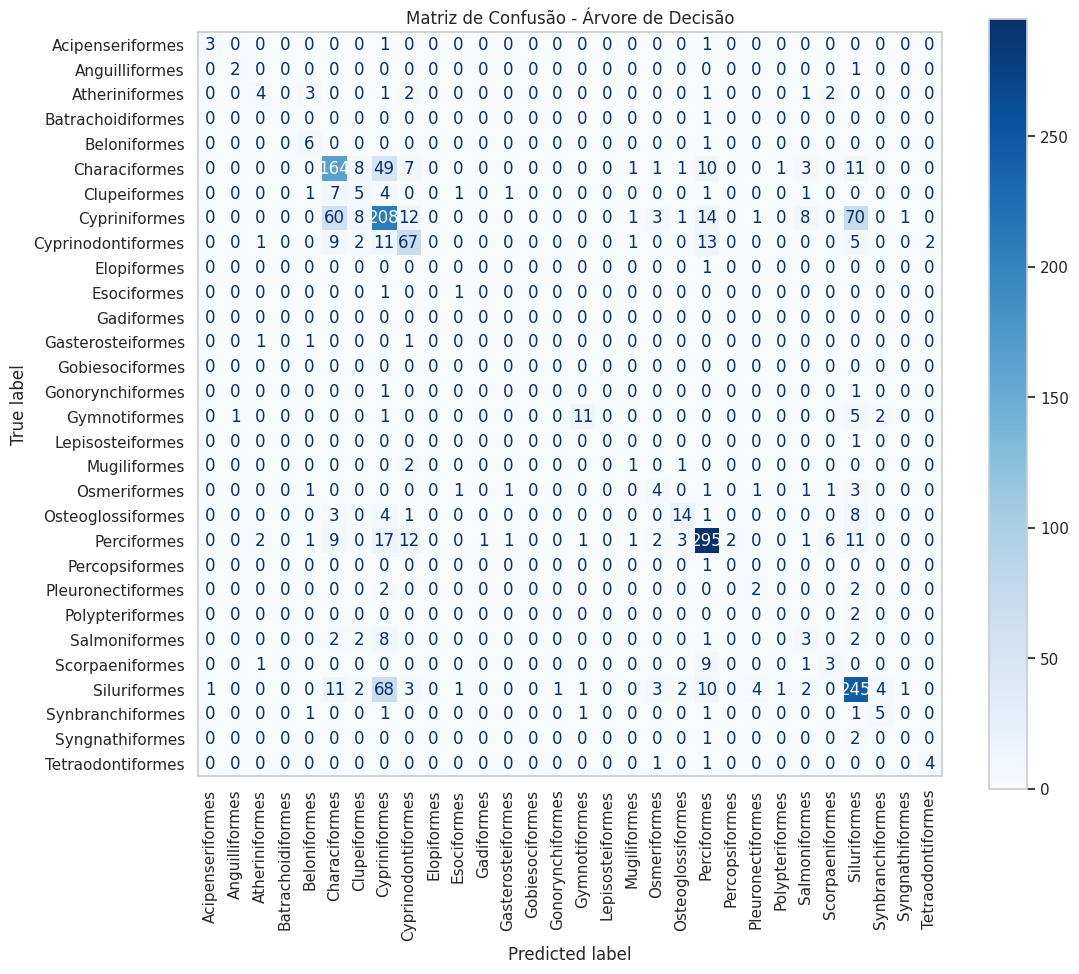

------------------------------------------------------------

Floresta Aleatória
Validação Cruzada (3-fold): 0.7590
Acurácia no Teste: 0.7896

                    precision    recall  f1-score   support

  Acipenseriformes       1.00      0.60      0.75         5
    Anguilliformes       1.00      0.67      0.80         3
    Atheriniformes       0.88      0.50      0.64        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       0.88      1.00      0.93         7
     Characiformes       0.77      0.79      0.78       256
      Clupeiformes       0.50      0.10      0.16        21
     Cypriniformes       0.70      0.75      0.73       387
Cyprinodontiformes       0.88      0.82      0.85       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       1.00      0.50      0.67         2
 Gasterosteiformes       0.00      0.00      0.00         3
  Gonorynchiformes       0.00      0.00      0.00         2
     Gymnotiform

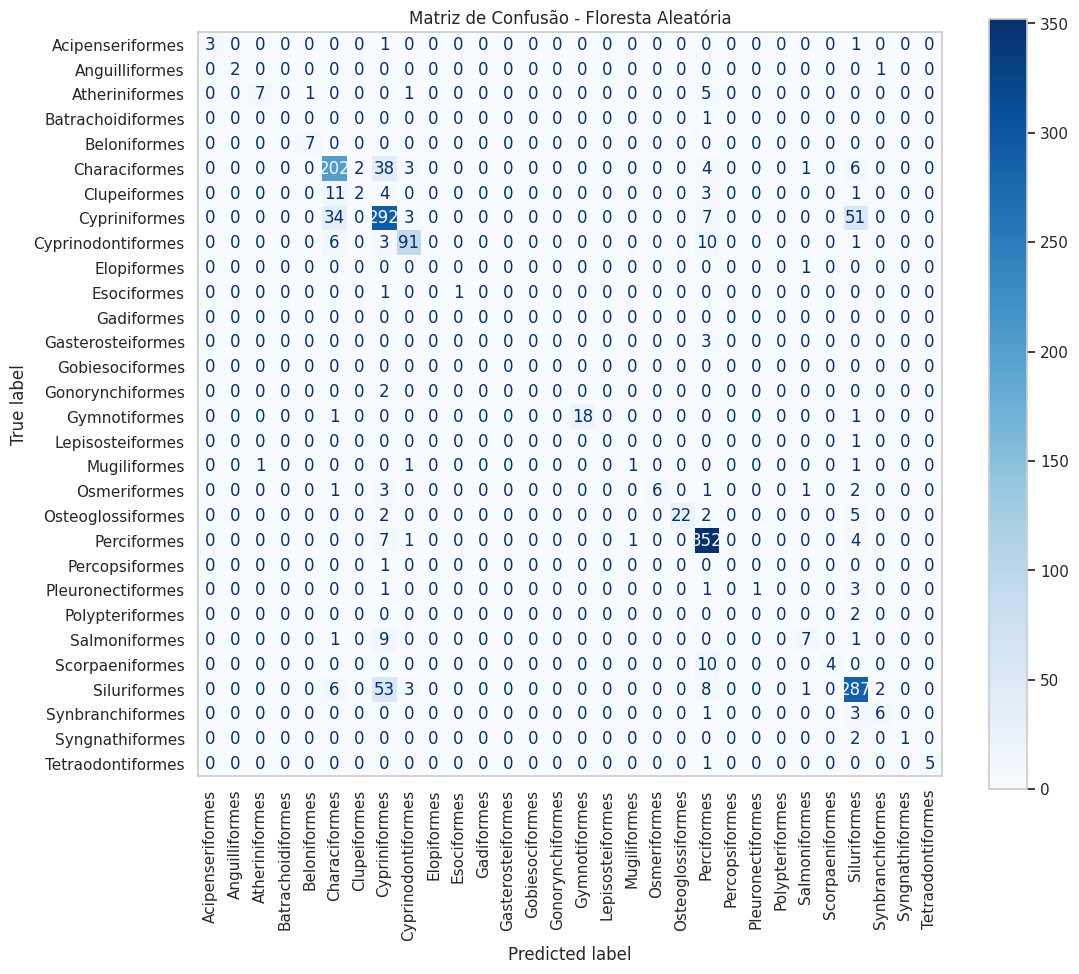

------------------------------------------------------------

Gradient Boosting
Validação Cruzada (3-fold): 0.7366
Acurácia no Teste: 0.7572

                    precision    recall  f1-score   support

  Acipenseriformes       0.60      0.60      0.60         5
    Anguilliformes       1.00      0.33      0.50         3
    Atheriniformes       0.42      0.57      0.48        14
 Batrachoidiformes       0.00      0.00      0.00         1
      Beloniformes       0.62      0.71      0.67         7
     Characiformes       0.76      0.75      0.75       256
      Clupeiformes       0.25      0.14      0.18        21
     Cypriniformes       0.68      0.74      0.71       387
Cyprinodontiformes       0.87      0.83      0.85       111
       Elopiformes       0.00      0.00      0.00         1
       Esociformes       0.33      0.50      0.40         2
        Gadiformes       0.00      0.00      0.00         0
 Gasterosteiformes       0.00      0.00      0.00         3
   Gobiesociforme

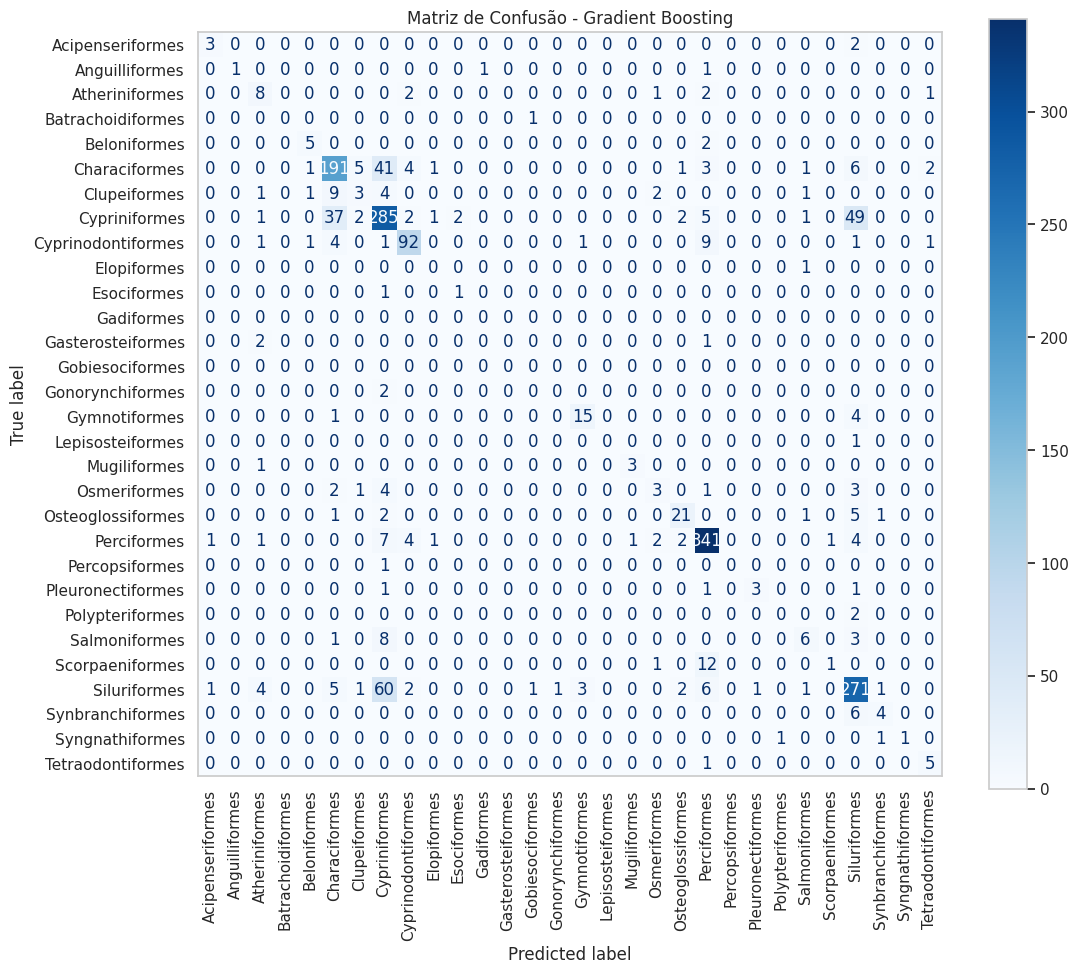

------------------------------------------------------------


In [ ]:
models = {
    "SVM (Linear)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='linear', random_state=42))]),
    "SVM (RBF)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', random_state=42))]),
    "SVM (Polinomial)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='poly', degree=3, random_state=42))]),
    "SVM (Sigmoide)": Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='sigmoid', random_state=42))]),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Floresta Aleatória": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    # Validação cruzada (3-fold ajustado para acomodar classes com poucas amostras)
    cv_scores = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy')

    # Treinamento e Predição
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'Acurácia Média (CV)': cv_scores.mean(),
        'Acurácia (Teste)': test_acc
    }

    print(f"\n{name}")
    print(f"Validação Cruzada (3-fold): {cv_scores.mean():.4f}")
    print(f"Acurácia no Teste: {test_acc:.4f}\n")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Matriz de Confusão usando dinamicamente os rótulos aprendidos pelo modelo
    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation='vertical')
    plt.title(f"Matriz de Confusão - {name}")
    plt.grid(False)
    plt.show()
    print("-" * 60)

In [ ]:
df_resumo = pd.DataFrame(results).T.sort_values(by='Acurácia (Teste)', ascending=False)
print("RESUMO COMPARATIVO DOS MODELOS")
display(df_resumo)

# Identificação dinâmica das colunas (funciona em português ou inglês)
col_cv = 'Acurácia Média (CV)' if 'Acurácia Média (CV)' in df_resumo.columns else ('Acurácia (CV)' if 'Acurácia (CV)' in df_resumo.columns else 'CV Mean Accuracy')
col_test = 'Acurácia (Teste)' if 'Acurácia (Teste)' in df_resumo.columns else 'Test Accuracy'

melhor_modelo = df_resumo.index[0]
acc_cv = df_resumo.loc[melhor_modelo, col_cv]
acc_test = df_resumo.loc[melhor_modelo, col_test]

print("\nDIAGNÓSTICO TÉCNICO")
print(f"Melhor Algoritmo Identificado: {melhor_modelo}")

if (acc_cv - acc_test) > 0.08:
    print("Diagnóstico: O modelo apresenta sinais de Alta Variância (Overfitting), o desempenho na validação cruzada superou o teste.")
elif acc_cv < 0.65 and acc_test < 0.65:
    print("Diagnóstico: O modelo apresenta sinais de Alto Viés (Underfitting), baixa capacidade de generalização nos dois conjuntos.")
else:
    print("Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.")

RESUMO COMPARATIVO DOS MODELOS


,Acurácia Média (CV),Acurácia (Teste)
SVM (RBF),0.759407,0.795564
Floresta Aleatória,0.758957,0.789568
Gradient Boosting,0.736621,0.757194
SVM (Linear),0.699897,0.718225
SVM (Polinomial),0.667666,0.714029
Árvore de Decisão,0.625394,0.627698
SVM (Sigmoide),0.520913,0.532974



DIAGNÓSTICO TÉCNICO
Melhor Algoritmo Identificado: SVM (RBF)
Diagnóstico: Modelo Equilibrado, boa capacidade de generalização com viés e variância sob controle.


---
# **Conclusão**

Esse trabalho teve como objetivo o treino e comparação dos modelos ensinados em sala afim de entendermos suas finalidades e quais tipos de problemas eles solucionam na prática.

#  **Como os modelos se sairam em cada dataset:**

1. ## *Breast Cancer Wisconsin (Diagnóstico Médico):*

 O **SVM (Linear e RBF)** e a **Floresta Aleatória** apresentaram as maiores taxas de acurácia e consistência na validação cruzada. A análise da Matriz de Confusão acabou focando na minimização dos *Falsos Negativos* (categorizar errados os tumores), garantindo alta **Recall** no apoio ao diagnóstico.

2. ## *Wine Price vs. Blind Quality (Preço vs. Qualidade Cega):*

Os modelos de *ensemble* foram melhores que os de SVM. A presença de múltiplas variáveis categóricas (codificadas através de *One-Hot Encoding*) e não-lineares beneficiou a divisão por limiares das árvores de decisão.

3. ## *Eleições de 1936 (Previsão Histórica por Estado):*

O **SVM Linear** e a **Floresta Aleatória** obtiveram ótima margem de separação na classificação binária dos estados. A padronização de dados via `StandardScaler` dentro do `Pipeline` foi essencial no SVM para equilibrar as escalas dos vetores de votos declarados e reais. Mesmo eu ainda não tendo entendido onde errei para fazer a devida ancoragem dos dados e acertar a previsão.

4. ## *Heart Disease Prediction Dataset*
A **Floresta Aleatória** teve o melhor equilíbrio com métricas firmes de *F1-Score* e *ROC-AUC*.

5. ## *Student stress actors a comprehensive analysis*

Apresentou um comportamento consistente onde os modelos de *ensemble* mantiveram o controlo da variância.

6. ## *FishMorph:*
 **SVM (RBF)** destacou-se com a maior acurácia no conjunto de teste (~79.5%), demonstrando excelente capacidade de lidar com dados morfológicos multidimensionais.


## 2. Comparativo entre SVM, Árvores e Ensembles

* *Support Vector Machine (SVM):*
  * **Ponto positivo** Muito eficiente em espaços de alta dimensão, demonstrando excelente margem de separação quando combinado com `StandardScaler` através do `Pipeline`.
  * **Ponto negativo:** Sensível à escala dos dados e com menor desempenho em cenários de alta sobreposição de classes quando utilizado com o kernel Sigmoide.

* *Árvore de Decisão (Decision Tree):*
  * **Pontos positivo** Simplicidade de interpretação e rápida execução.
  * **Ponto negativo:** Tendência a apresentar sinais de **Overfitting** quando a profundidade máxima não é limitada, ajustando-se excessivamente ao conjunto de treino.

* *Floresta Aleatória e Gradient Boosting (Ensembles):*
  * **Ponto positivo:** Mais estáveis e capazes de generalizar na maioria dos testes. A combinação de múltiplas árvores reduziu significativamente a variância (Floresta Aleatória) e o erro residual (Gradient Boosting).
  * **Vantagem:** Apresentam menor dependência de padronização estrita das variáveis, mais flexível.

De modo geral, os algoritmos de **Ensemble** se sairam bem na maioria dos cenários de teste. Contudo, o **SVM (especialmente com os kernels Linear e RBF)** provou ser um modelo altamente competitivo quando os dados são devidamente padronizados, destacando as abordagens como ferramentas indispensáveis no conjunto de técnicas de Machine Learning.